In [1]:
# rsync -av --progress /scratch/franzihe/input/COMBLE u6030275@notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data 

In [2]:
import os
import pathlib
import sys
import socket
from pathlib import Path

hostname = socket.gethostname()

abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]


if "mimi" in hostname:
    print(hostname)
    DATA_DIR = "/scratch/franzihe/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity/"

elif "augustiner" in hostname: 
    DATA_DIR = "/home/franzihe/Data/"
    FIG_DIR = "/home/franzihe/Documents/Figures/mrr_reflectivity/"

INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

## Import python packages

* `Python` environment requirements: file requirements_retrieval.txt
* load `python` packages from imports.py
* load `functions` from functions.py



In [3]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt,radar, np, DateFormatter, datetime)


In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
plt.rc('font', size=21) #controls default text size
plt.rcParams["font.serif"]= ['DejaVu Serif']
levels = np.arange(-20, 30,0.5)

In [6]:
sites = ["ANX", "ALOMAR"]
years = ["2021", "2022"]

In [7]:
mrr_in_dict = {}
ds_dict = {}
for site in sites:
    for year in years:
        mrr_in_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'MRR_islas/maahn/*{}*{}*'.format(site, year))))
        try:
            ds_dict['{}.{}'.format(site, year)] = xr.open_mfdataset(mrr_in_dict['{}.{}'.format(site, year)], decode_times=True, )
            print("Reading files for {} in {}".format(site, year))
        except OSError:
            ds_dict['{}.{}'.format(site, year)] = xr.Dataset()
            # print("No files to open for {} in {}".format(site, year))
            continue

Reading files for ANX in 2021
Reading files for ANX in 2022
Reading files for ALOMAR in 2021


/home/franzihe/anaconda3/envs/retrieval/lib/python3.7/site-packages/matplotlib/contour.py:1483: UserWarning: Warning: converting a masked element to nan.
  self.zmax = float(z.max())
/home/franzihe/anaconda3/envs/retrieval/lib/python3.7/site-packages/matplotlib/contour.py:1484: UserWarning: Warning: converting a masked element to nan.
  self.zmin = float(z.min())
/home/franzihe/anaconda3/envs/retrieval/lib/python3.7/site-packages/matplotlib/contour.py:1483: UserWarning: Warning: converting a masked element to nan.
  self.zmax = float(z.max())
/home/franzihe/anaconda3/envs/retrieval/lib/python3.7/site-packages/matplotlib/contour.py:1484: UserWarning: Warning: converting a masked element to nan.
  self.zmin = float(z.min())


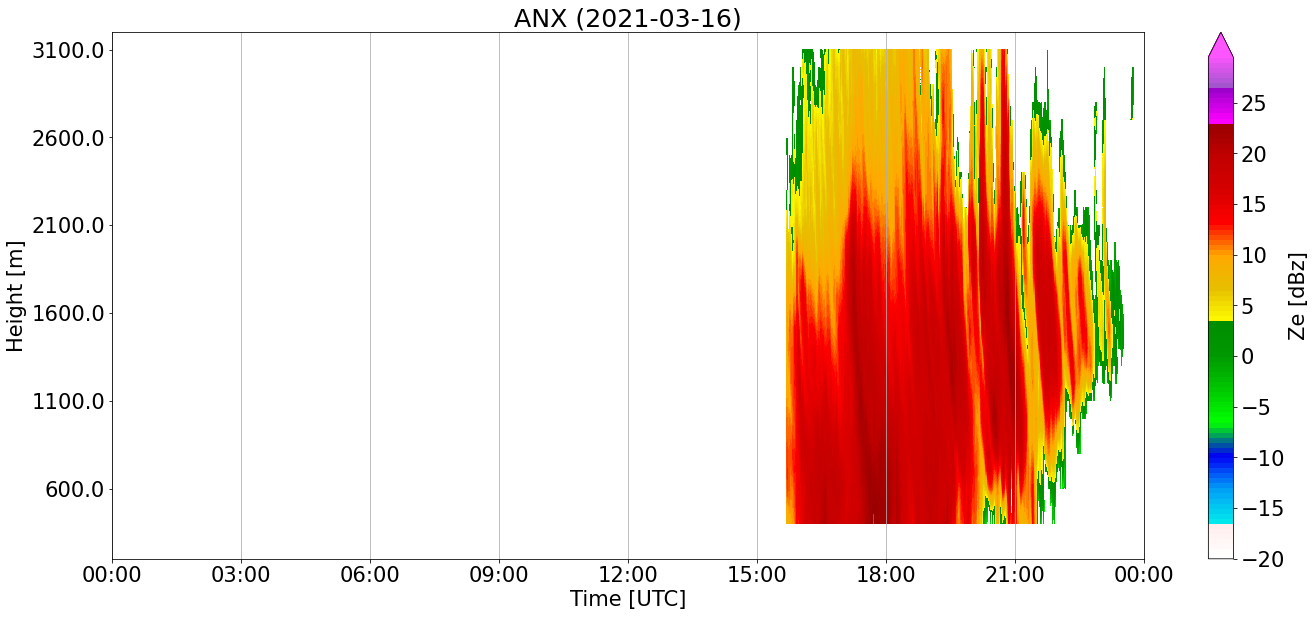

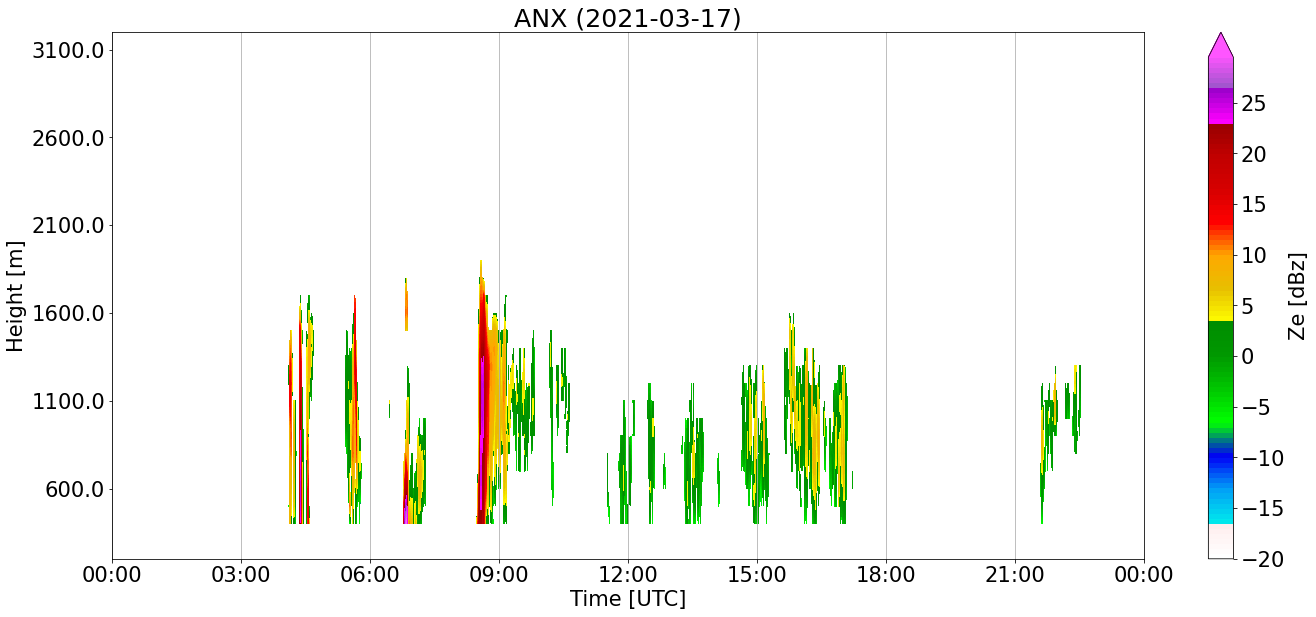

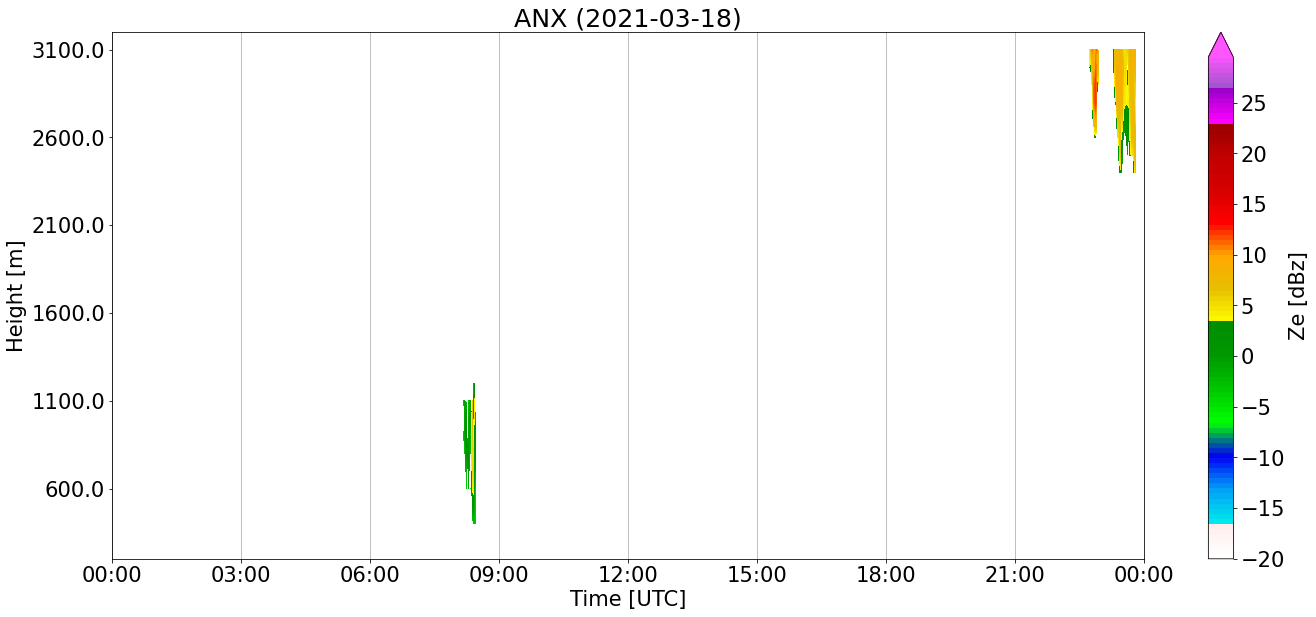

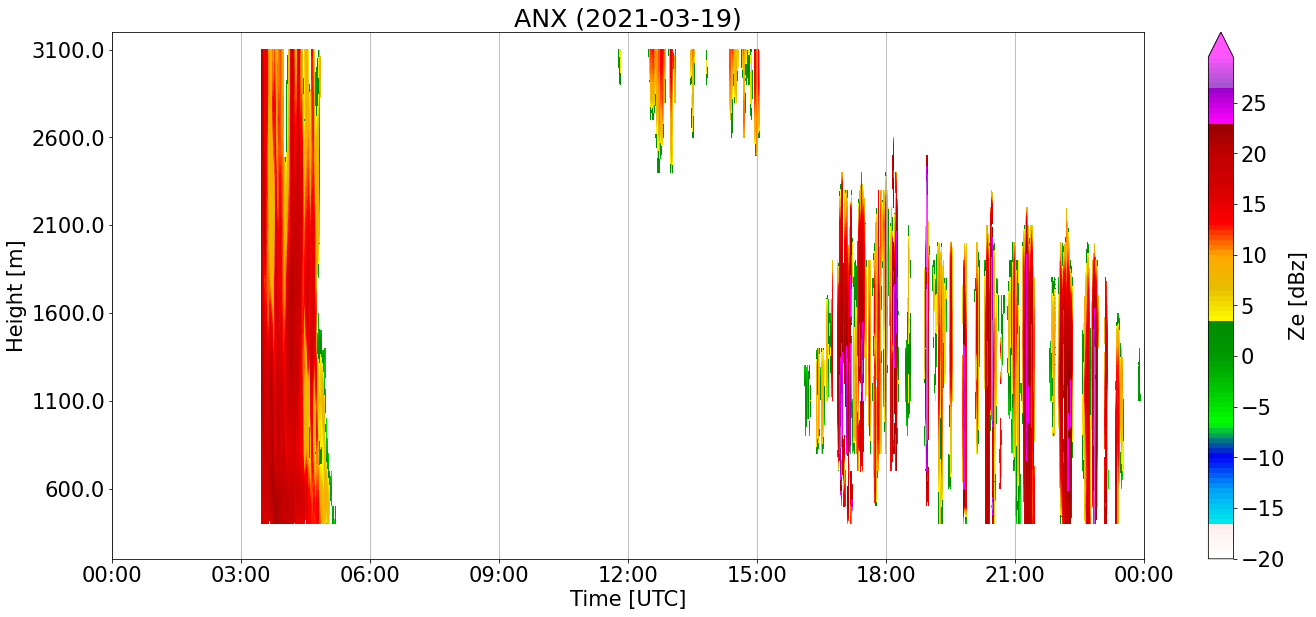

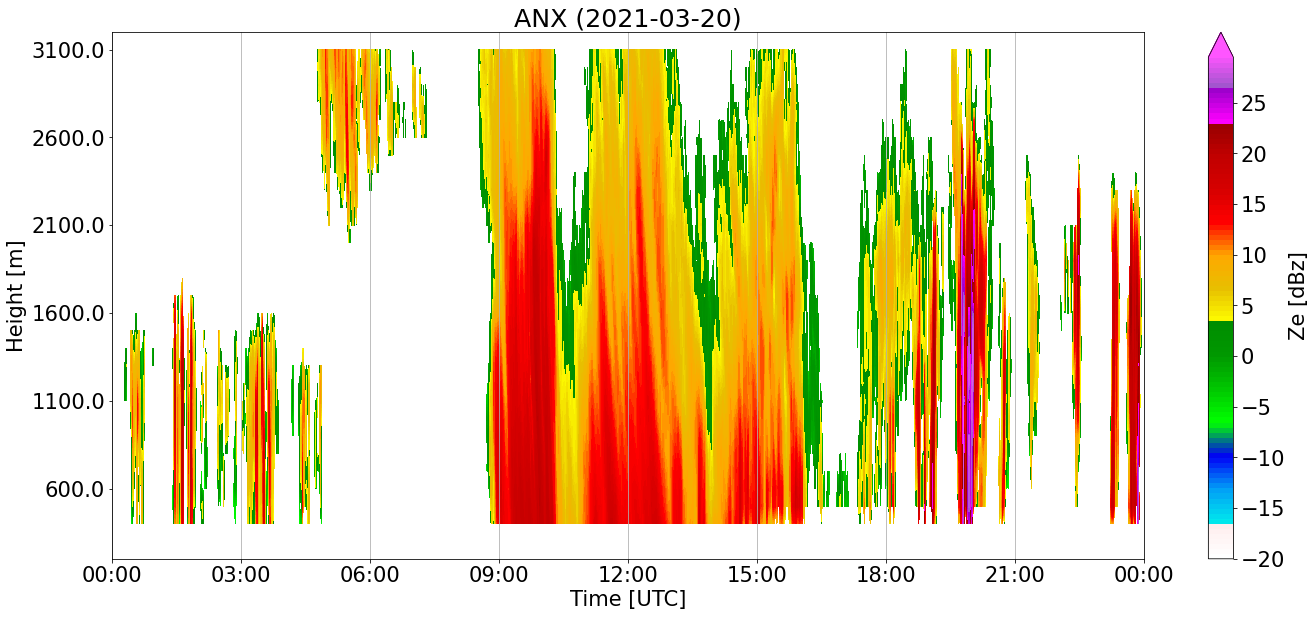

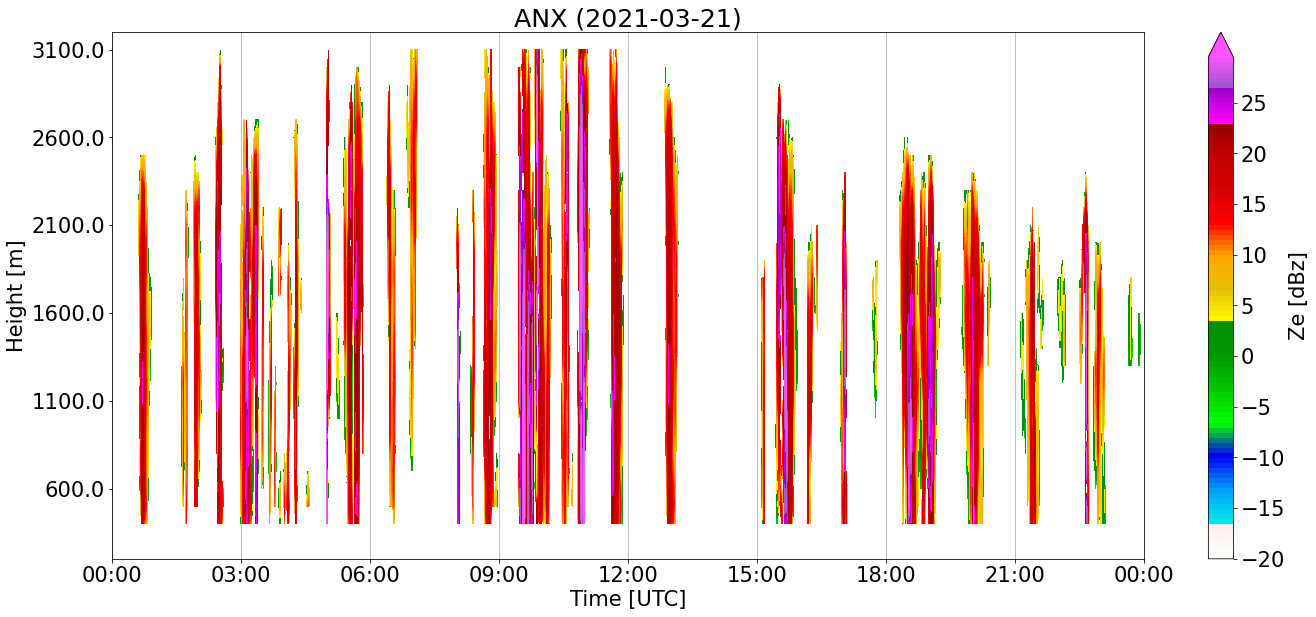

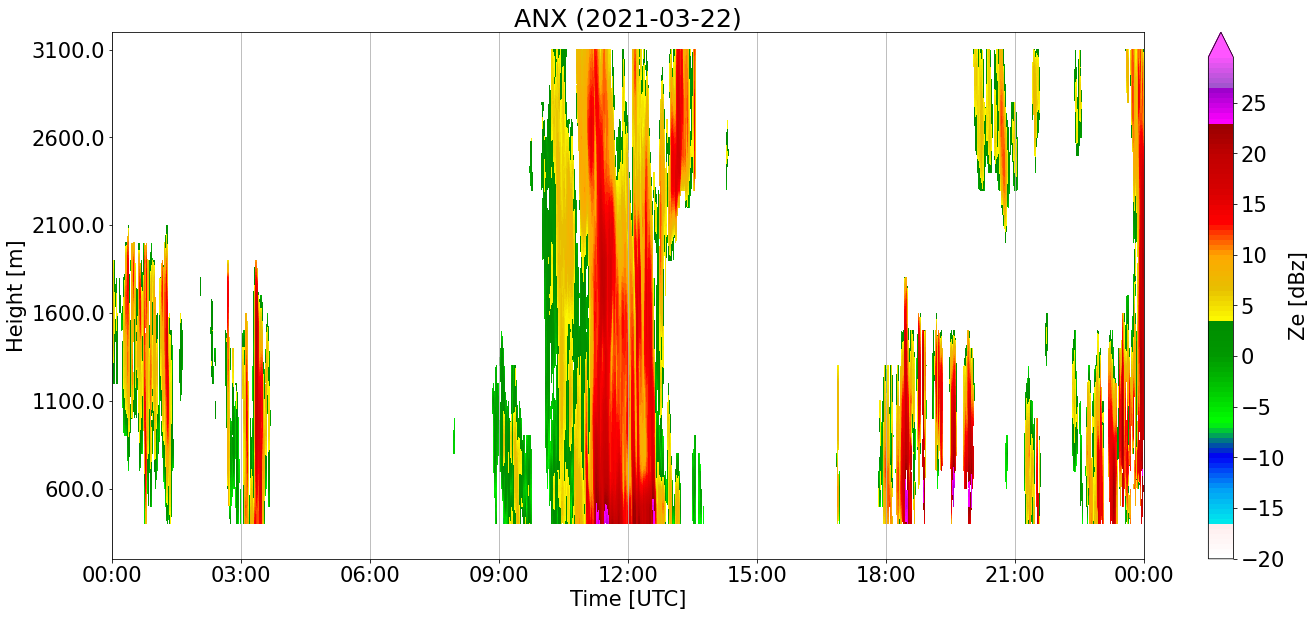

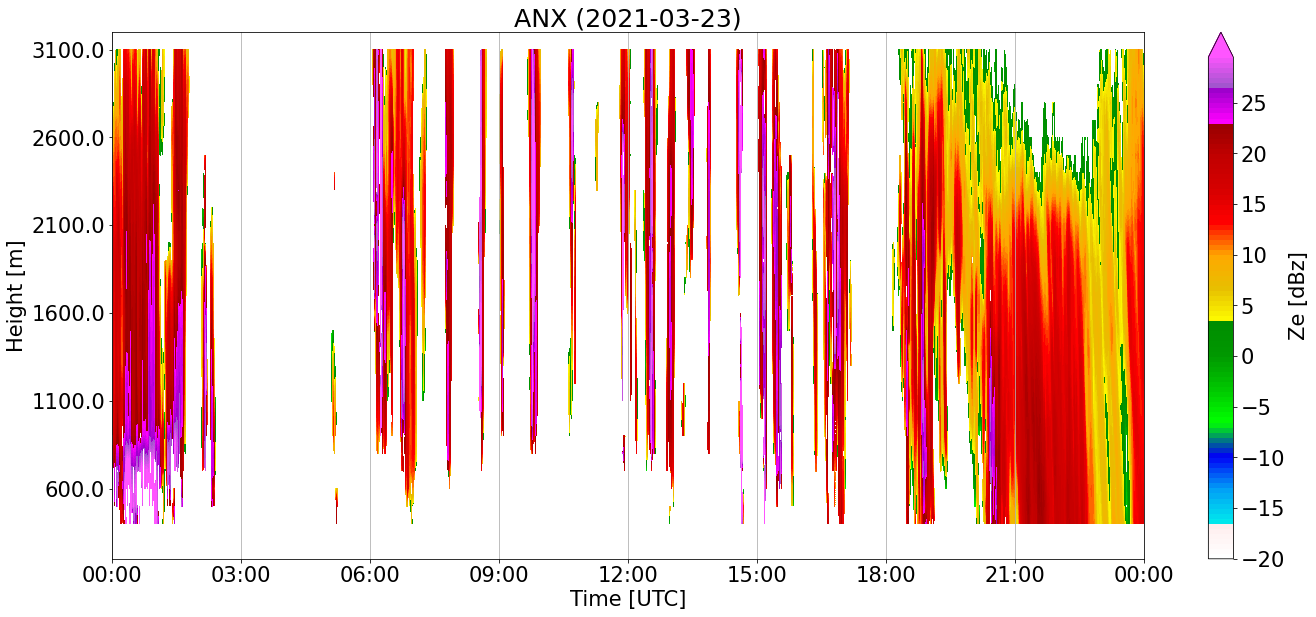

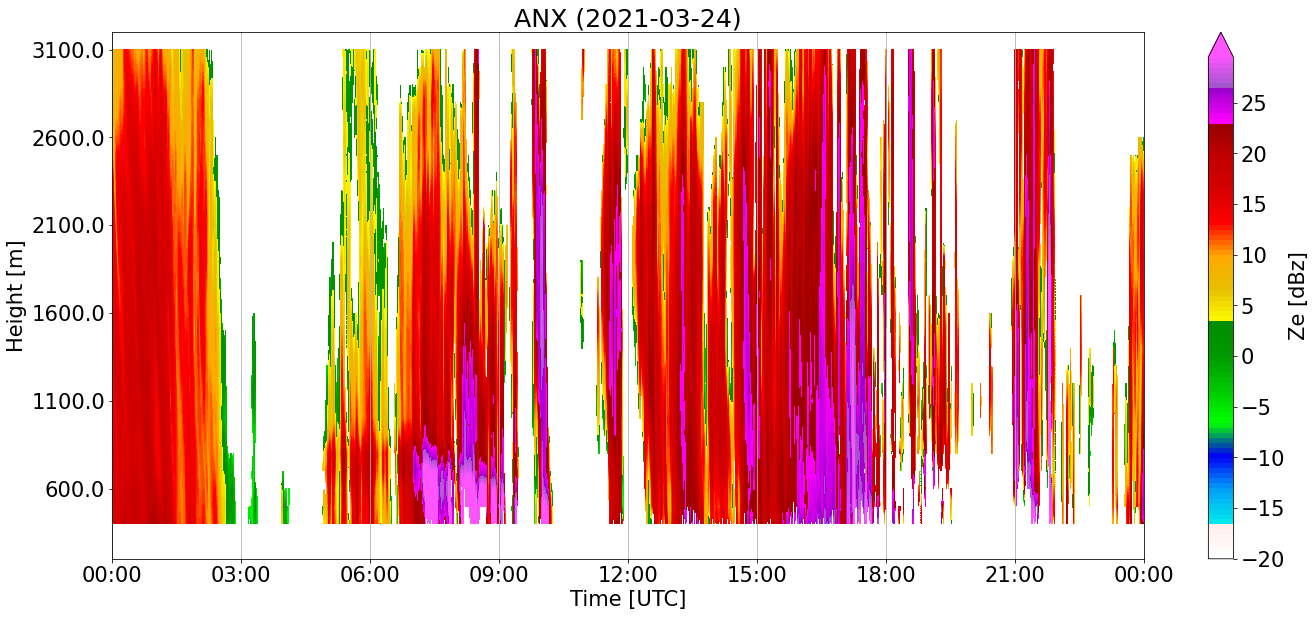

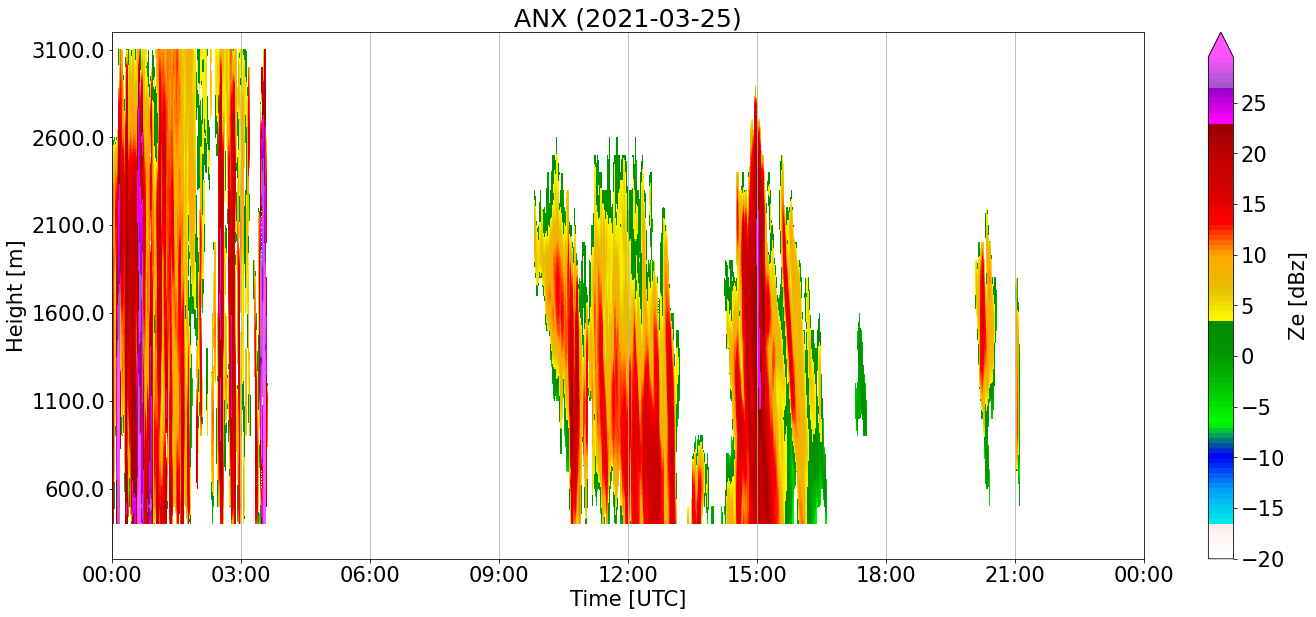

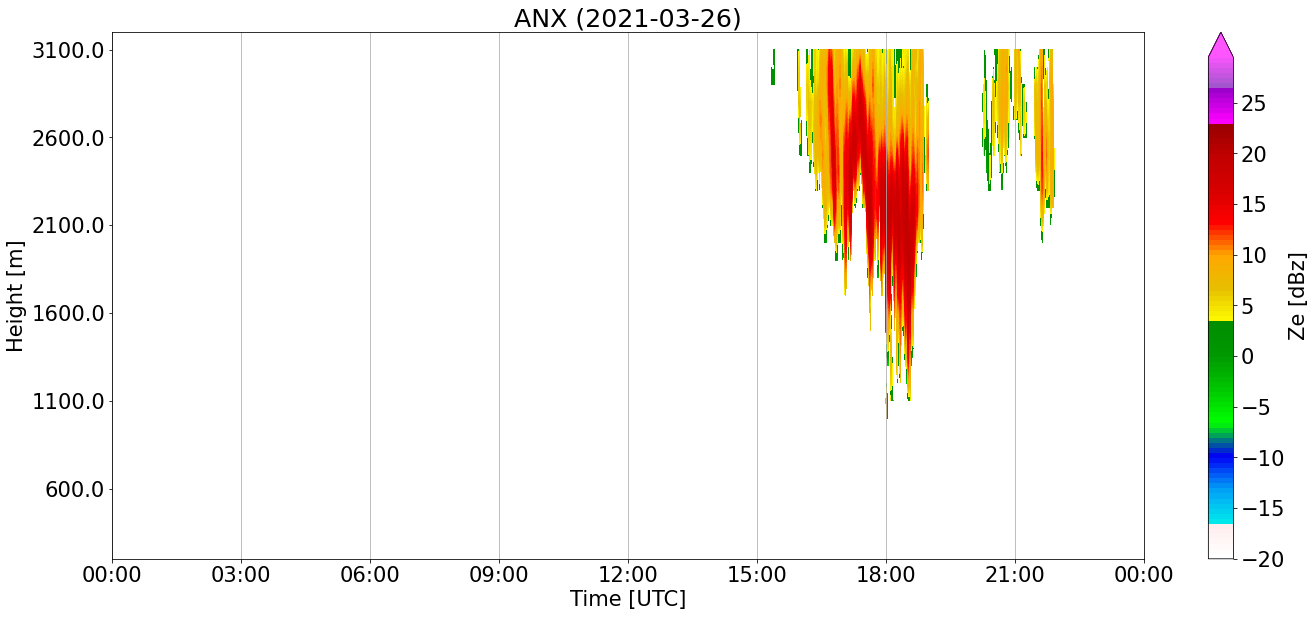

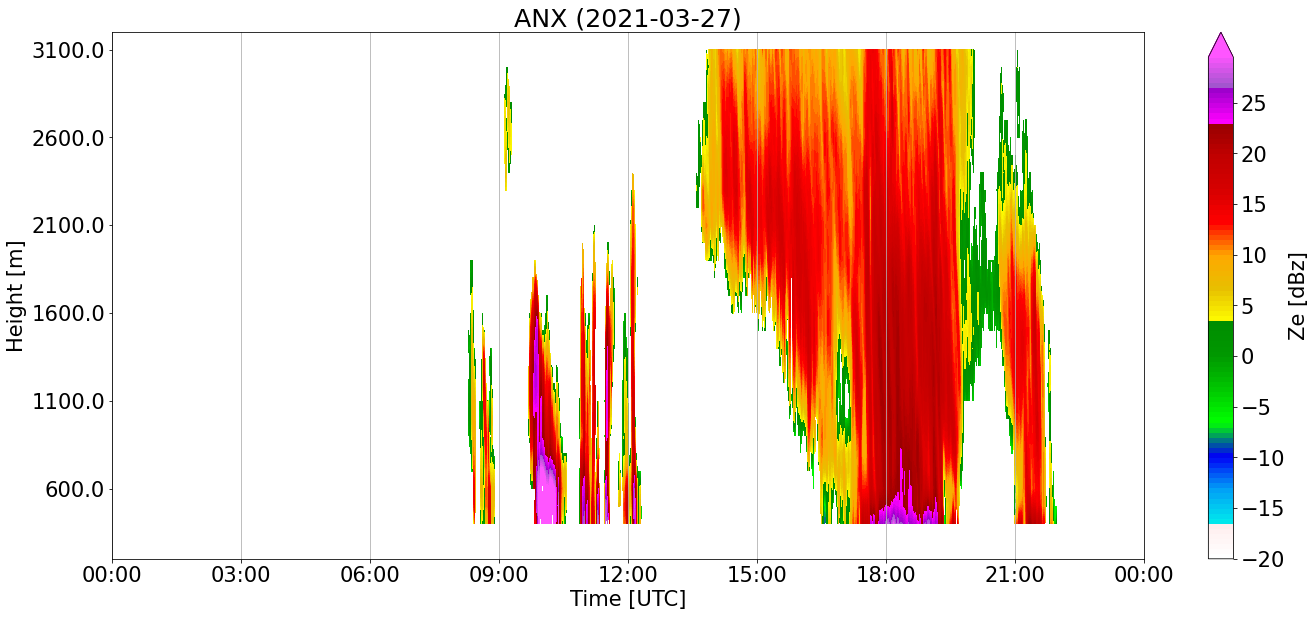

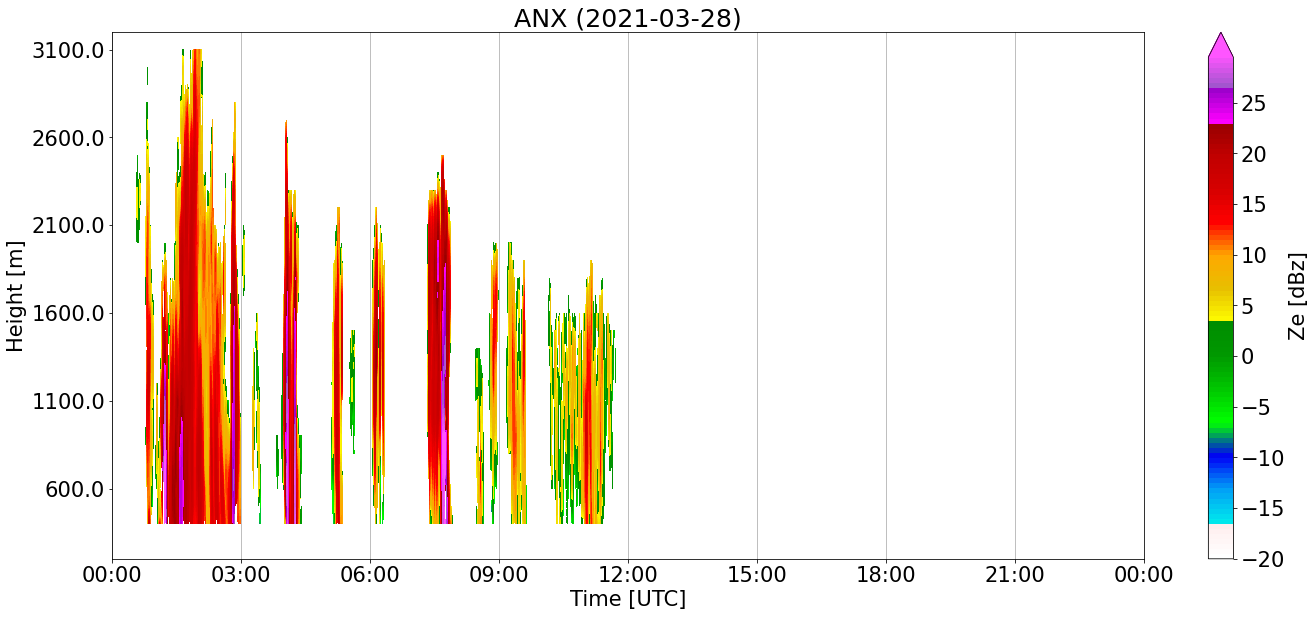

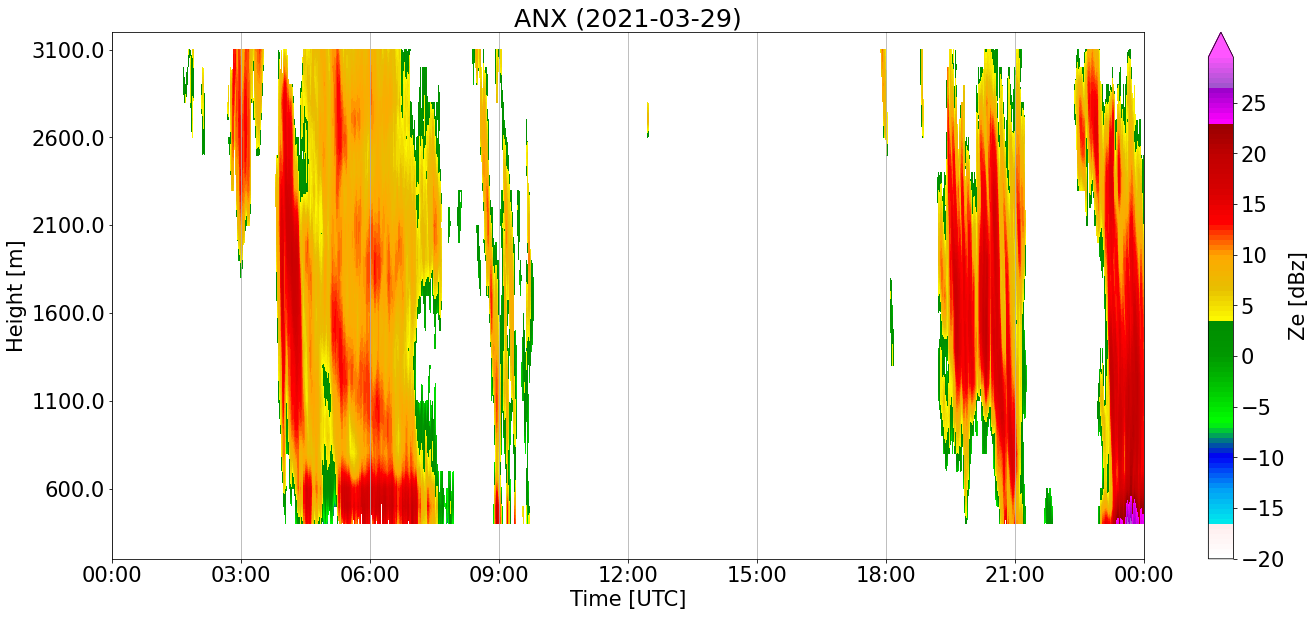

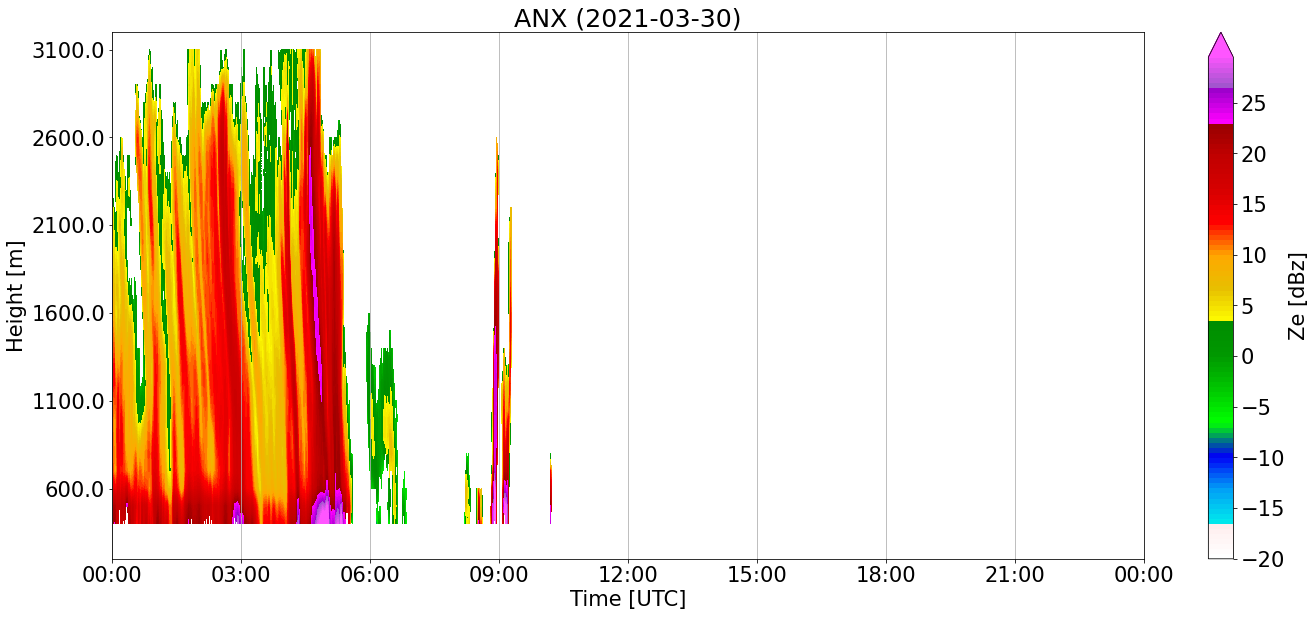

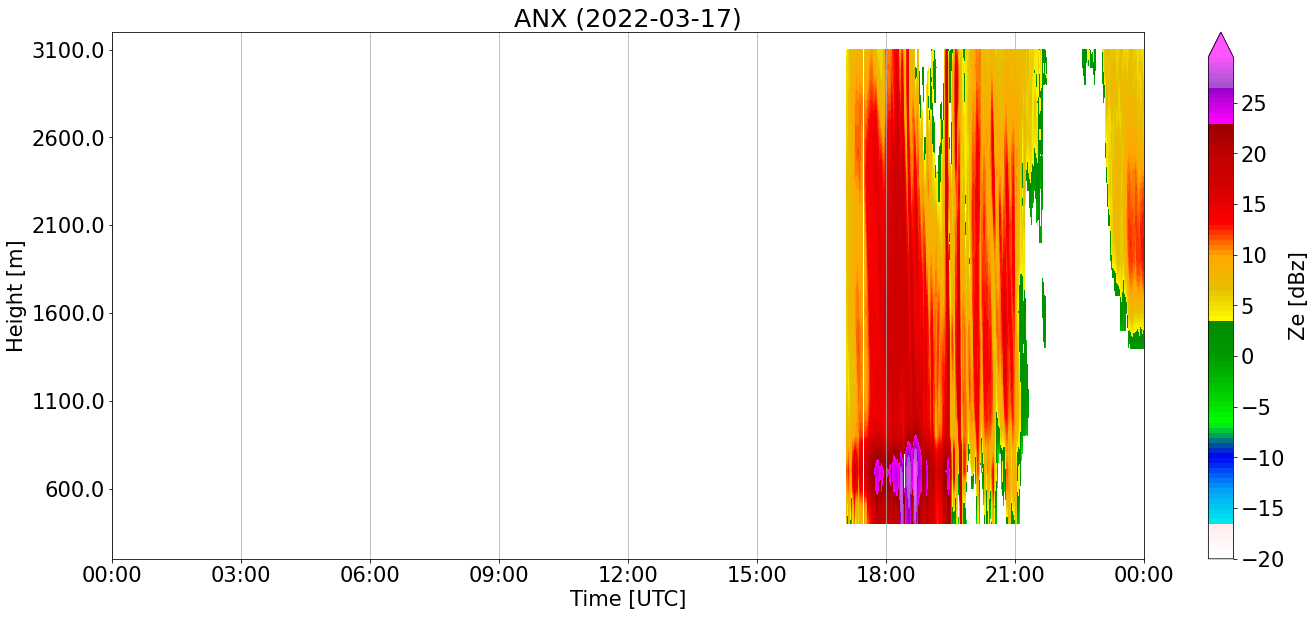

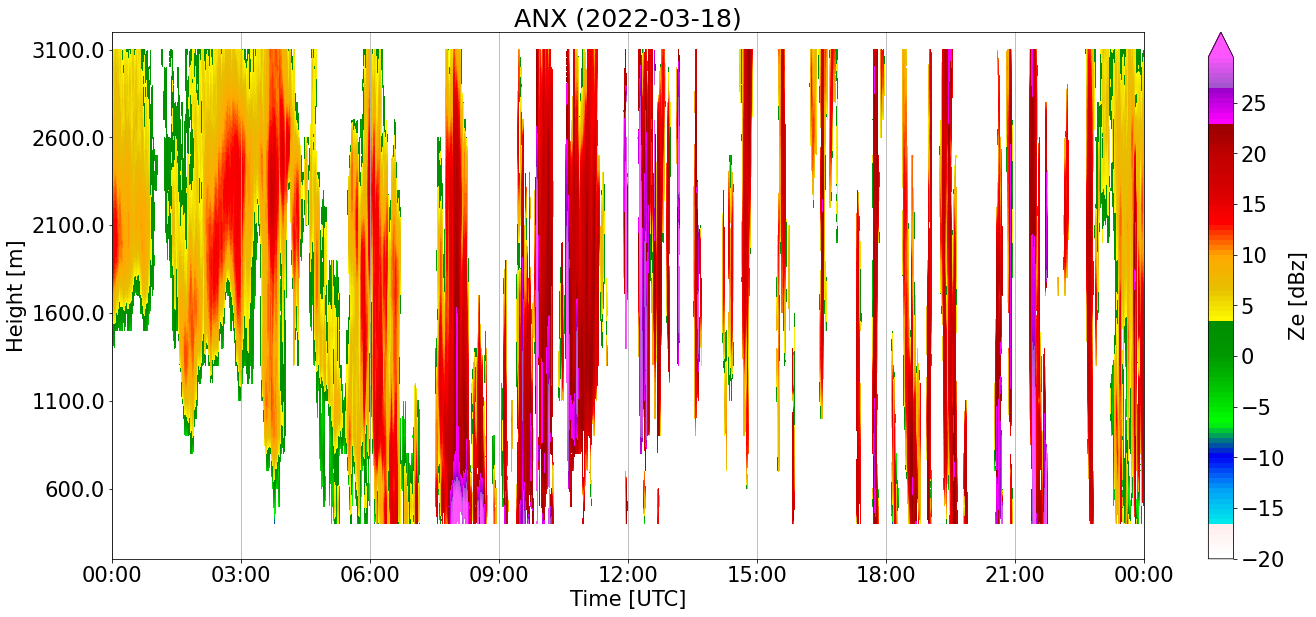

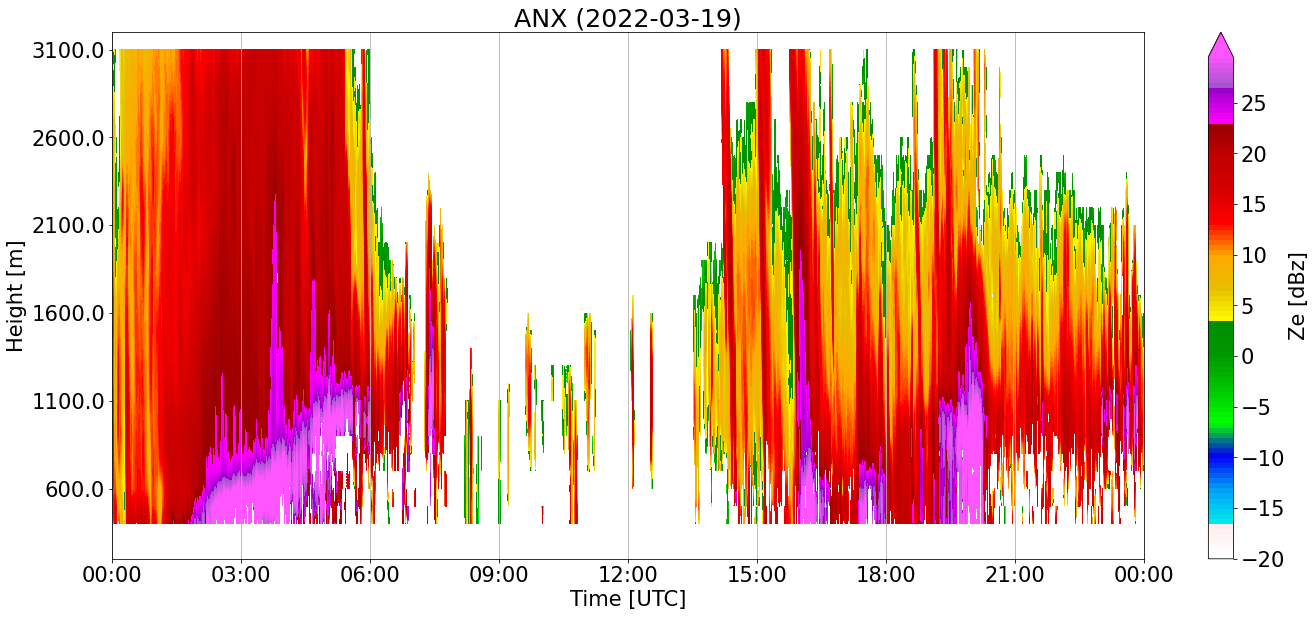

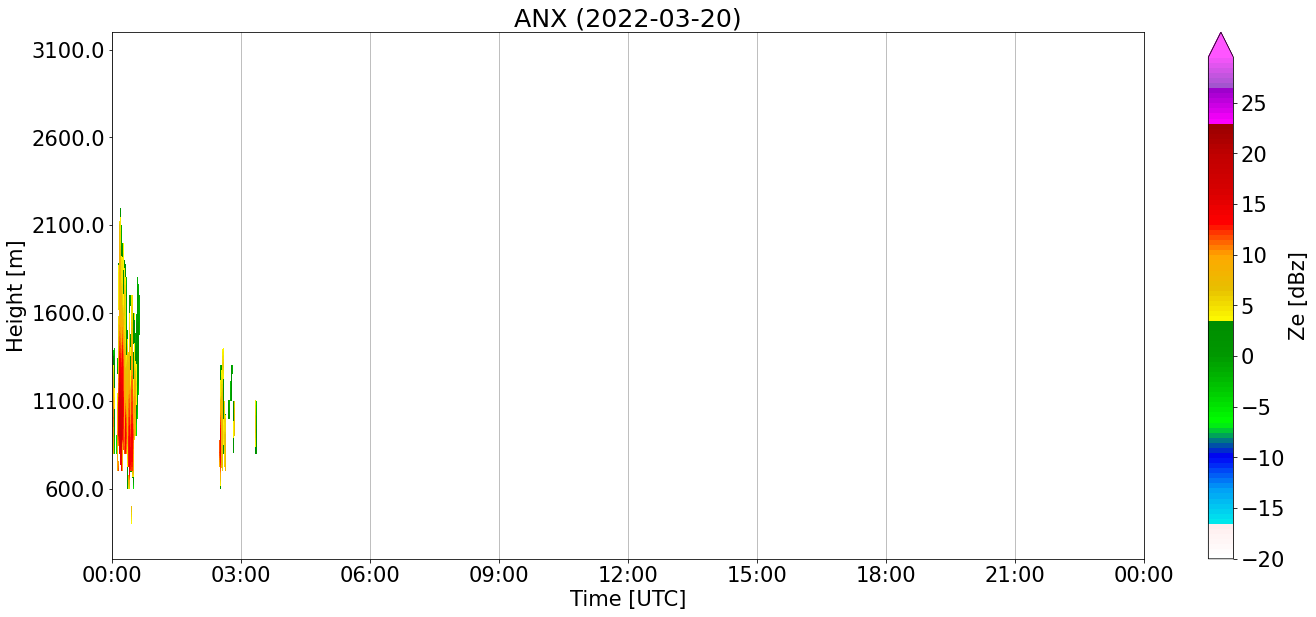

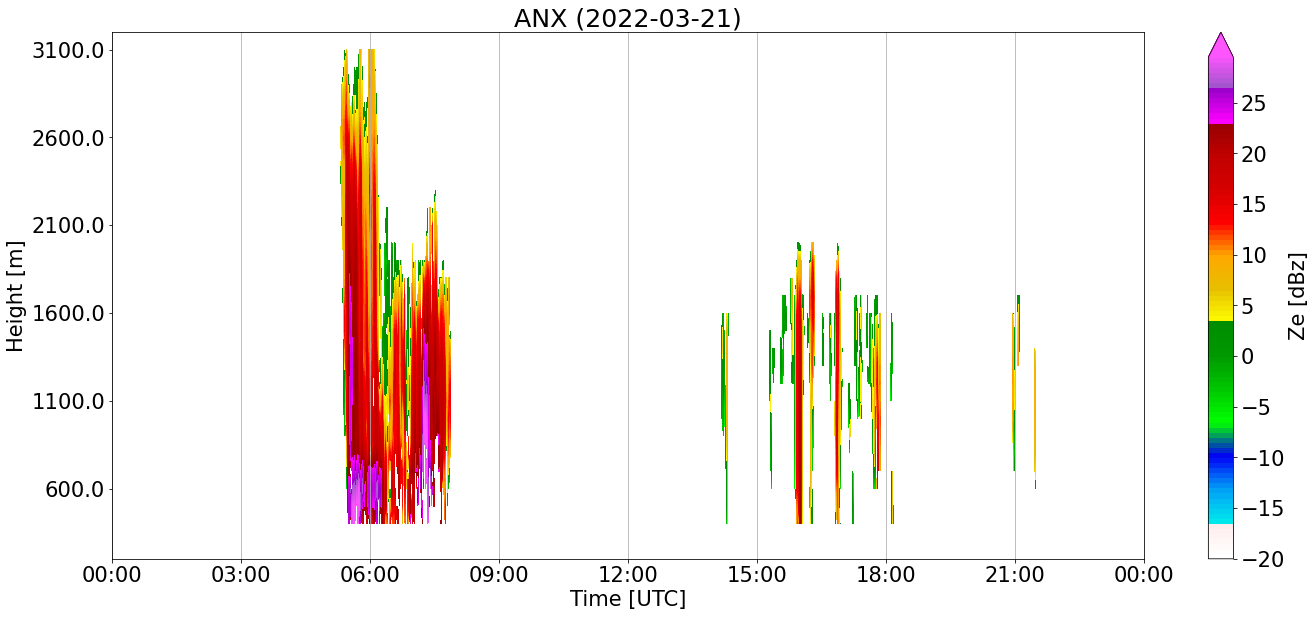

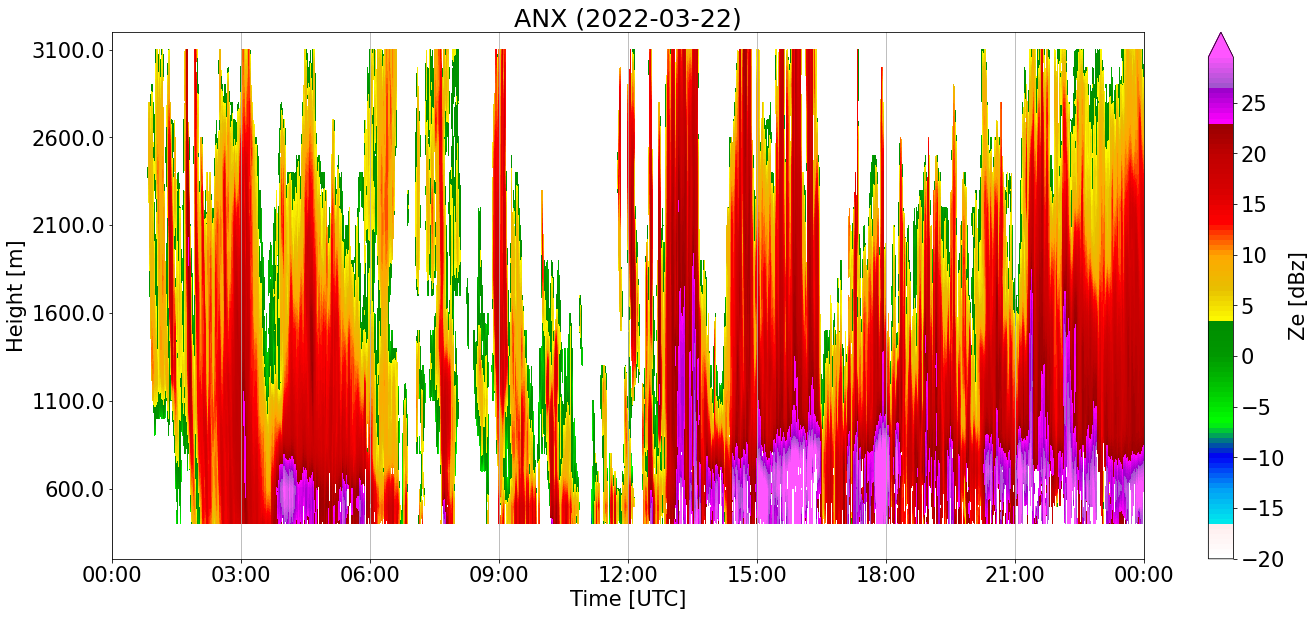

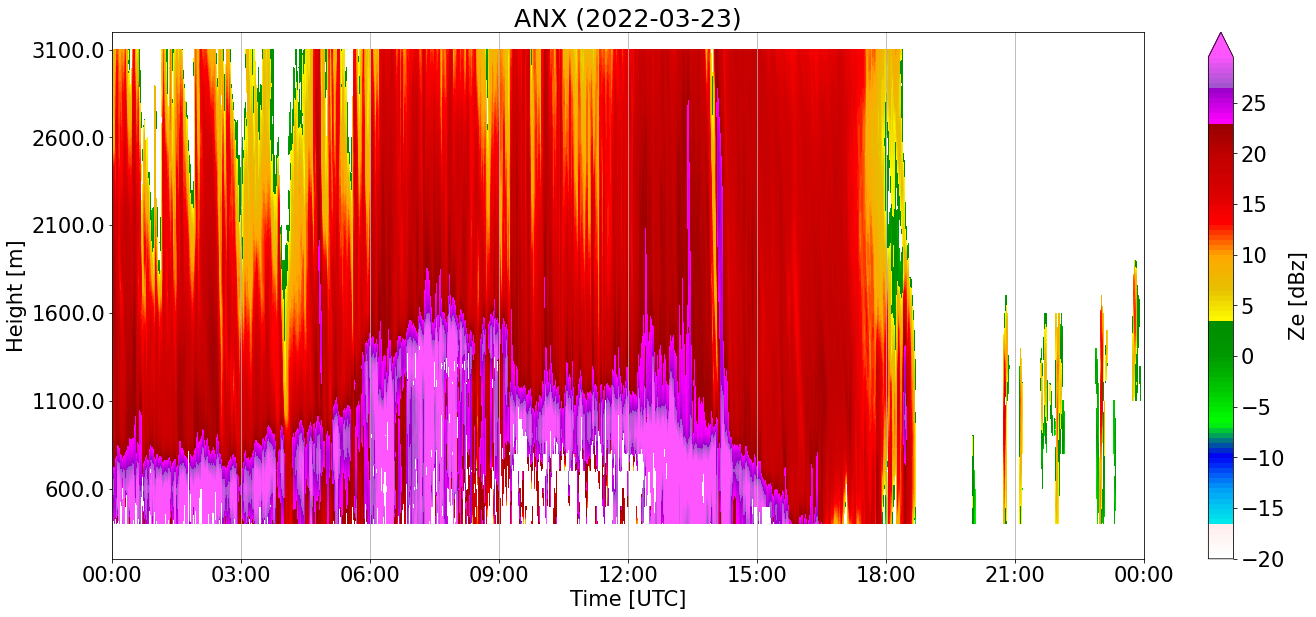

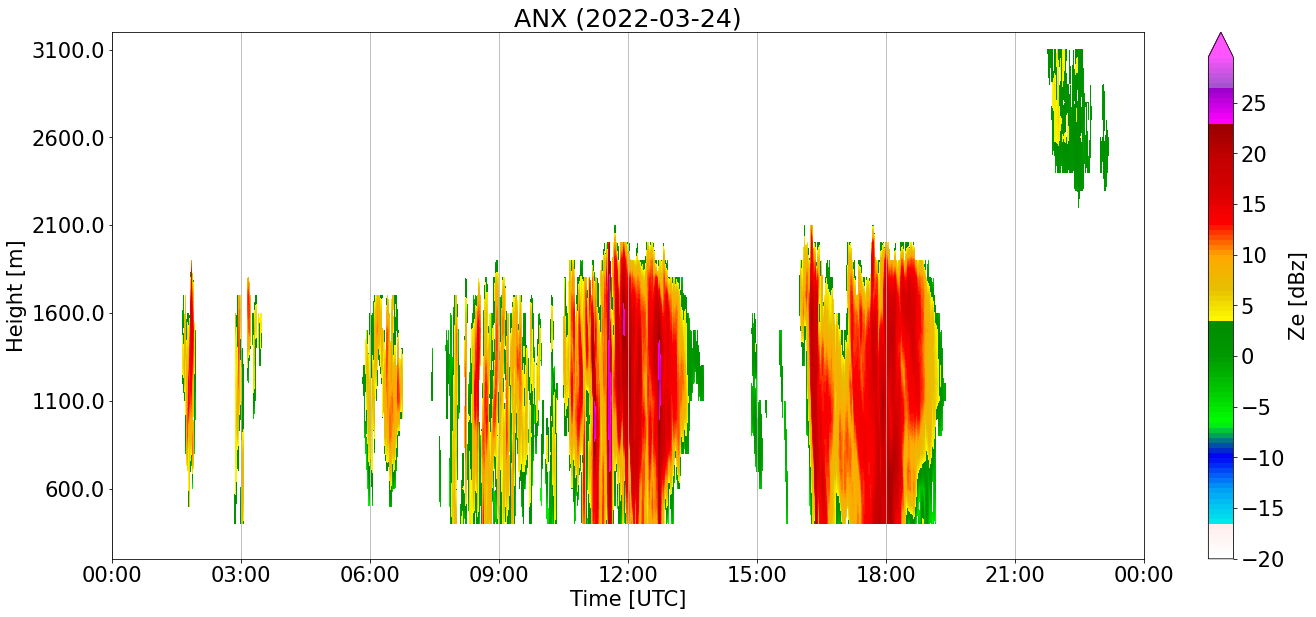

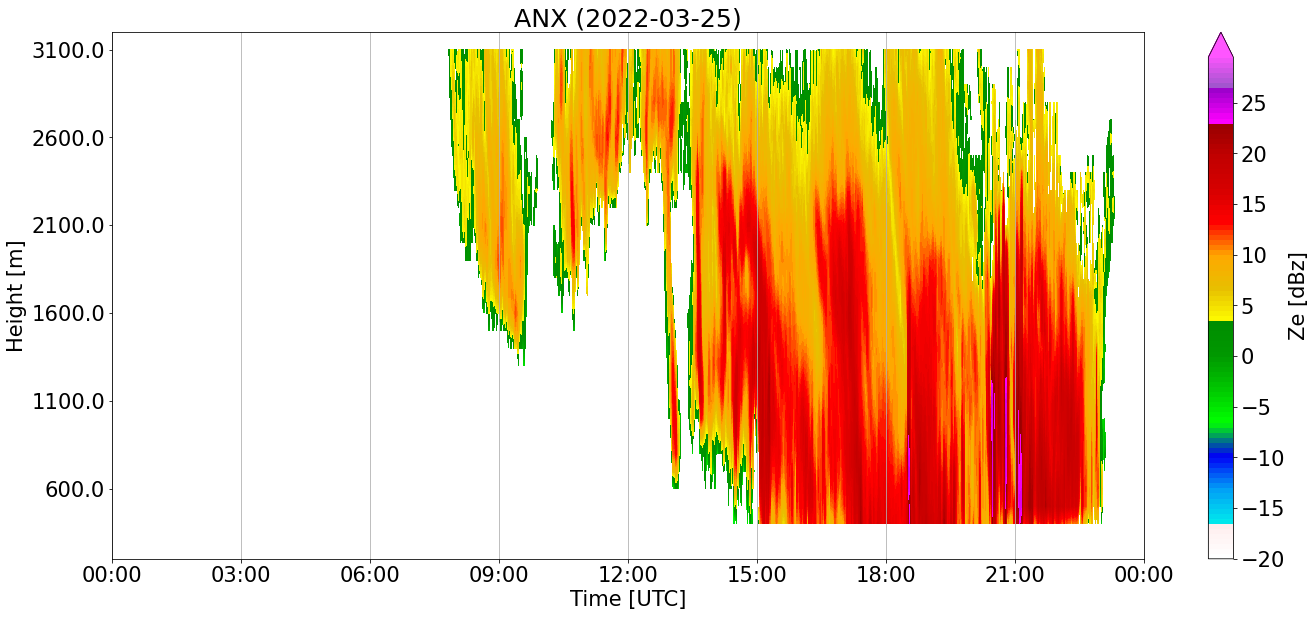

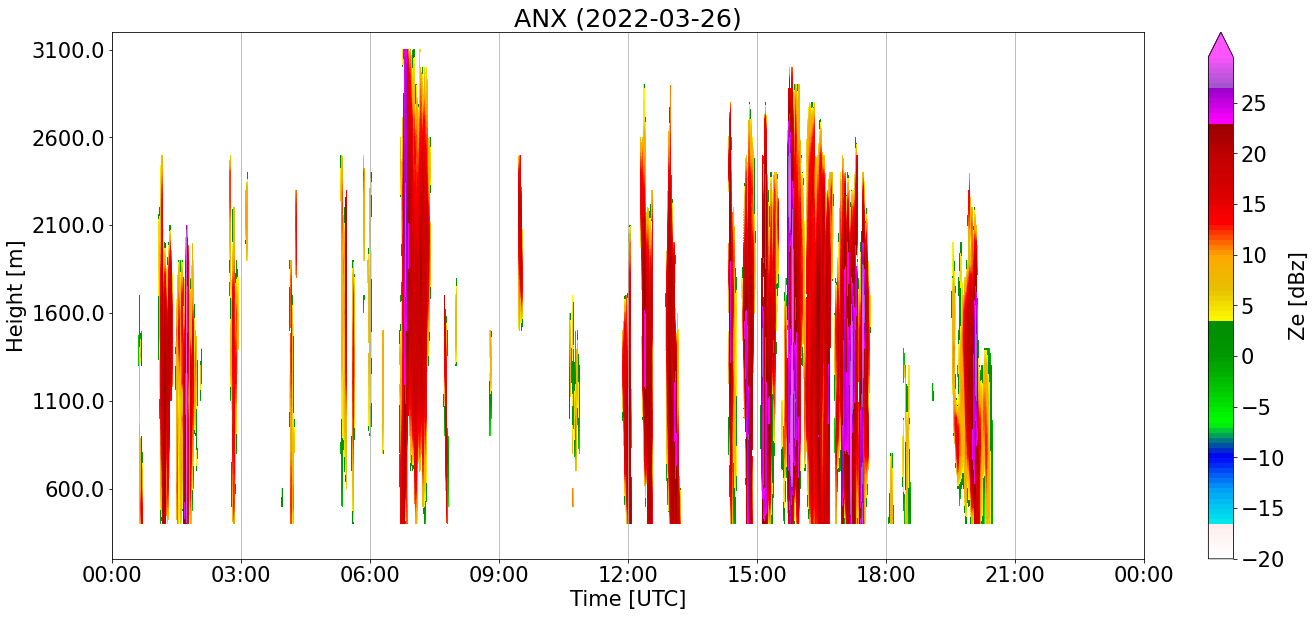

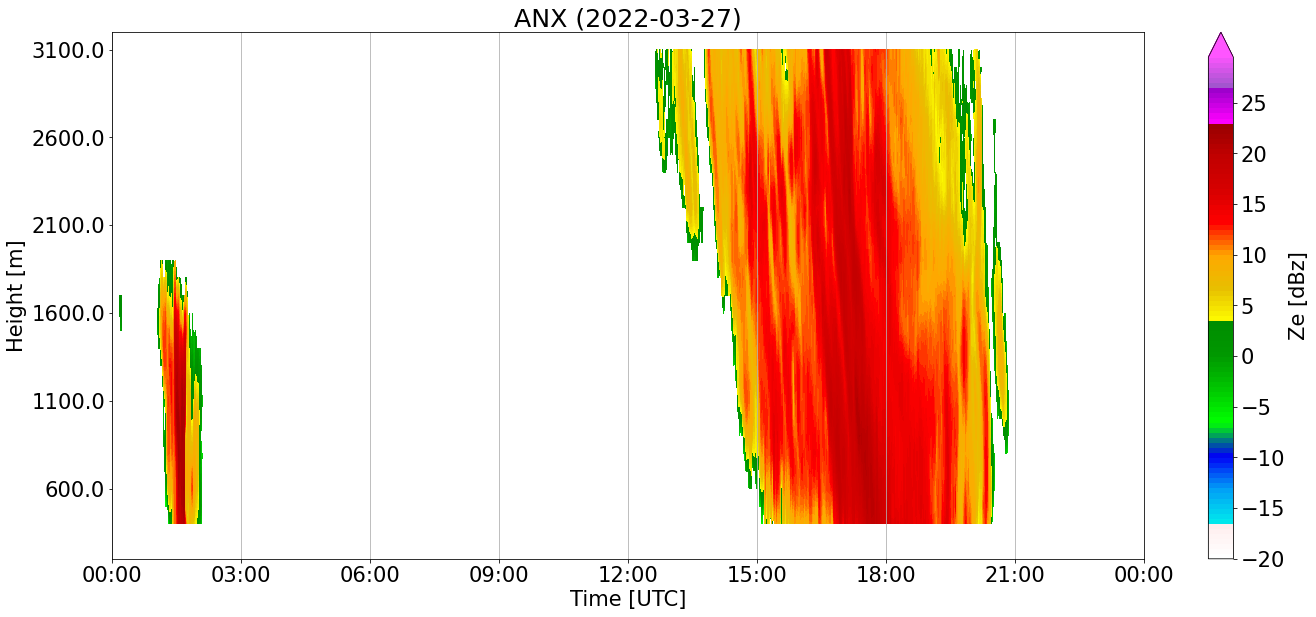

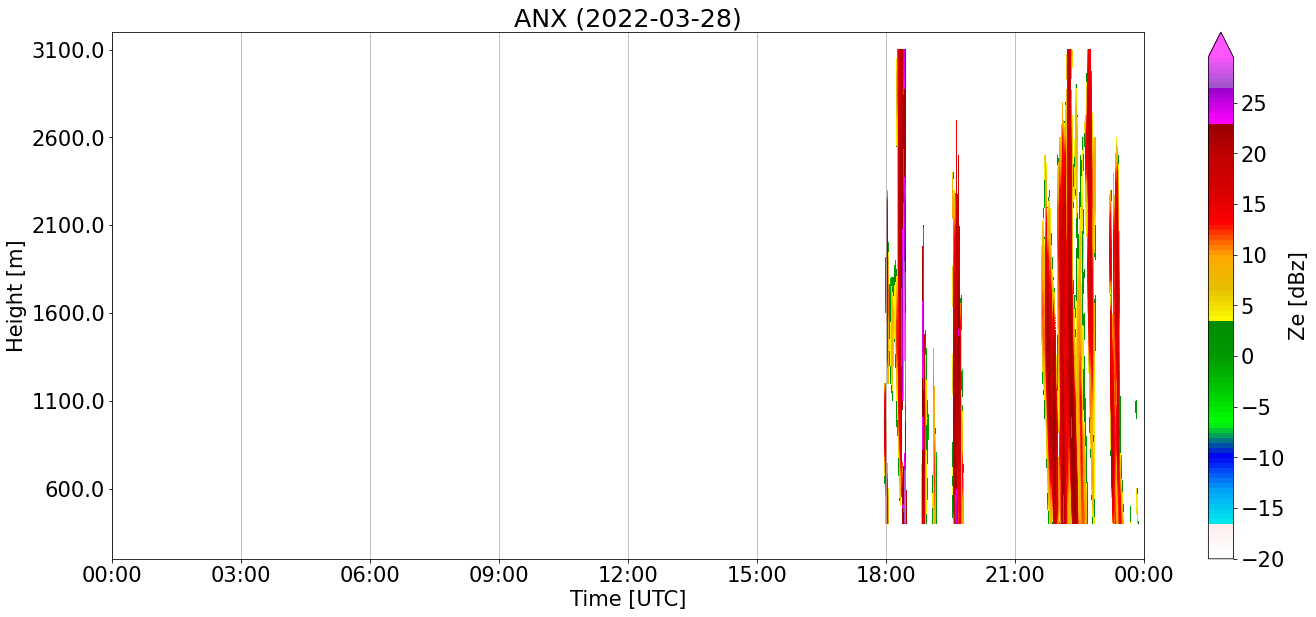

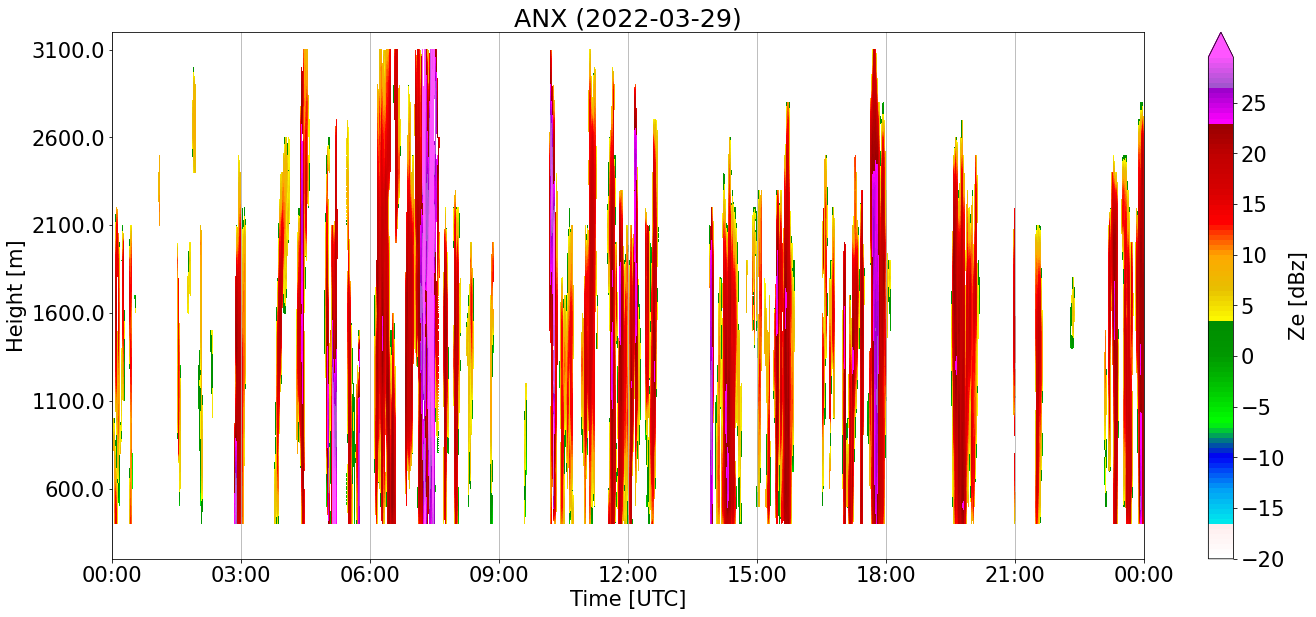

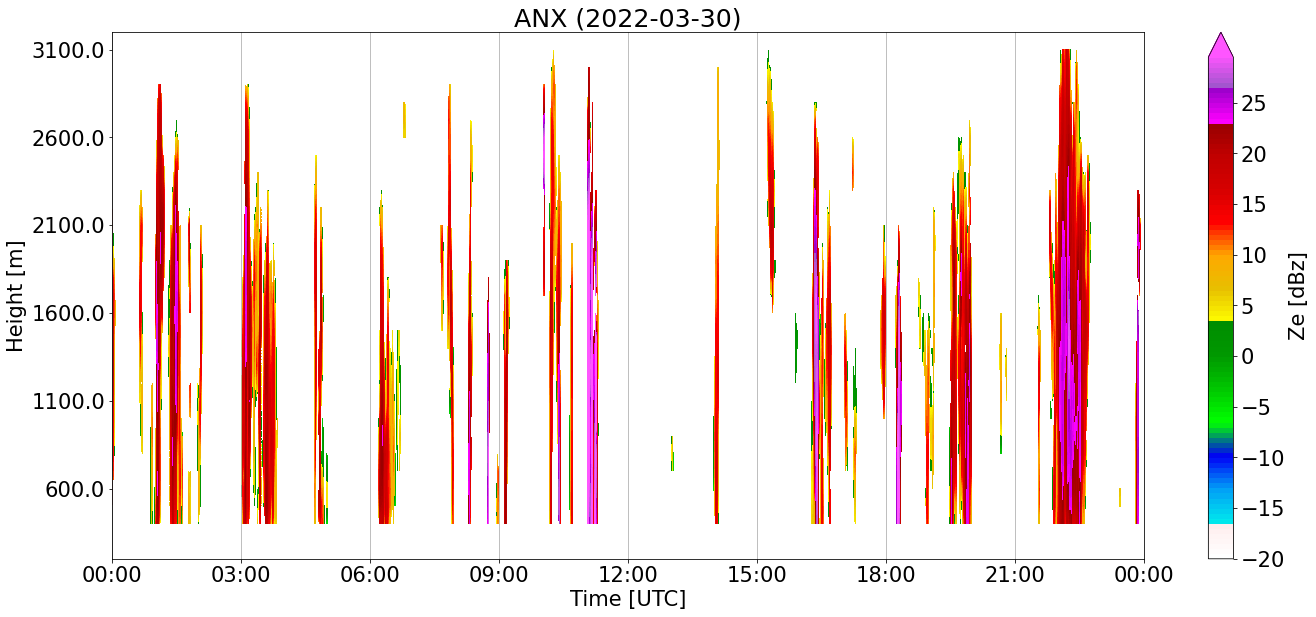

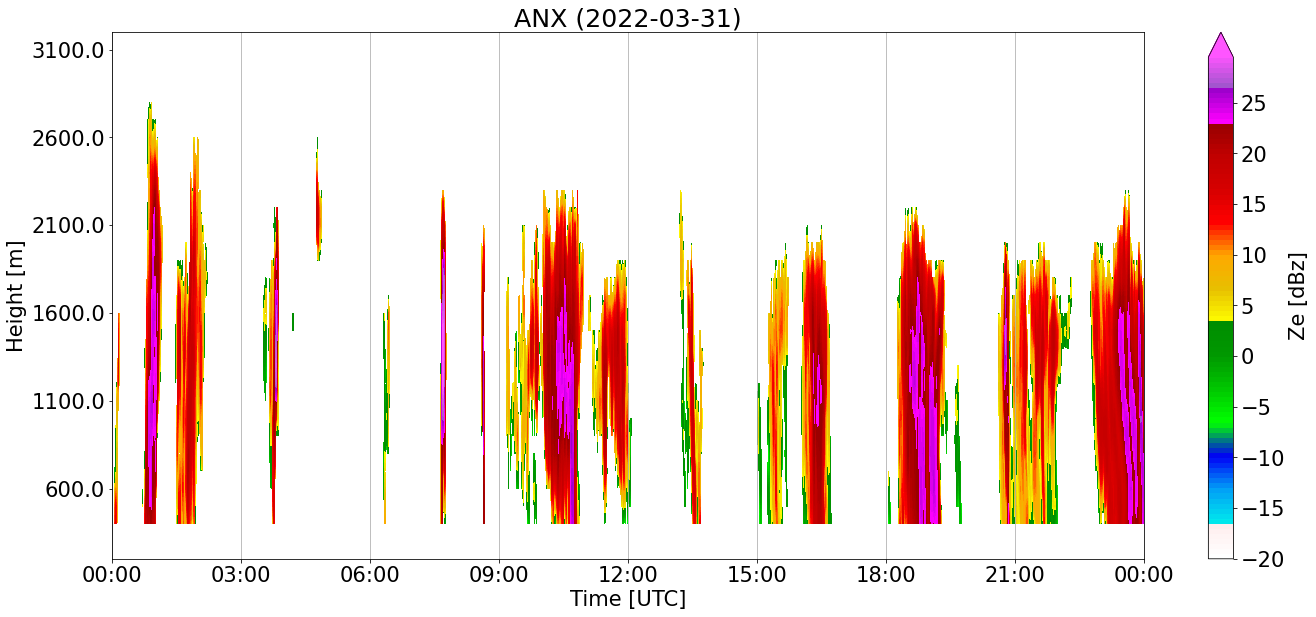

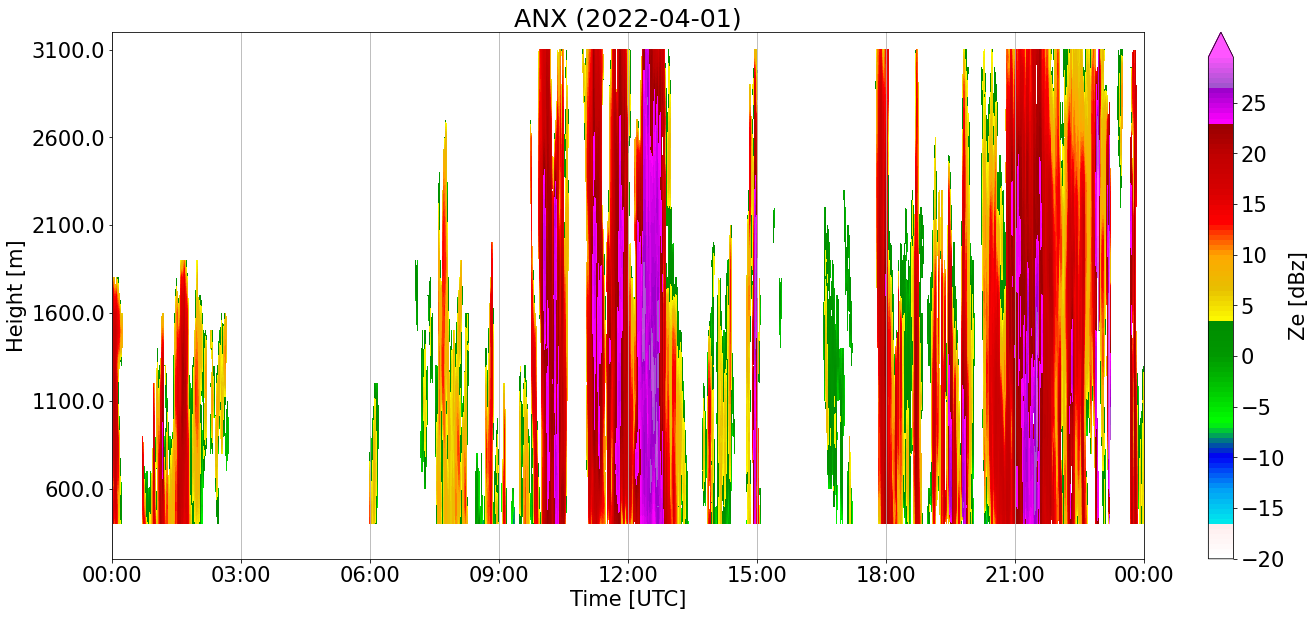

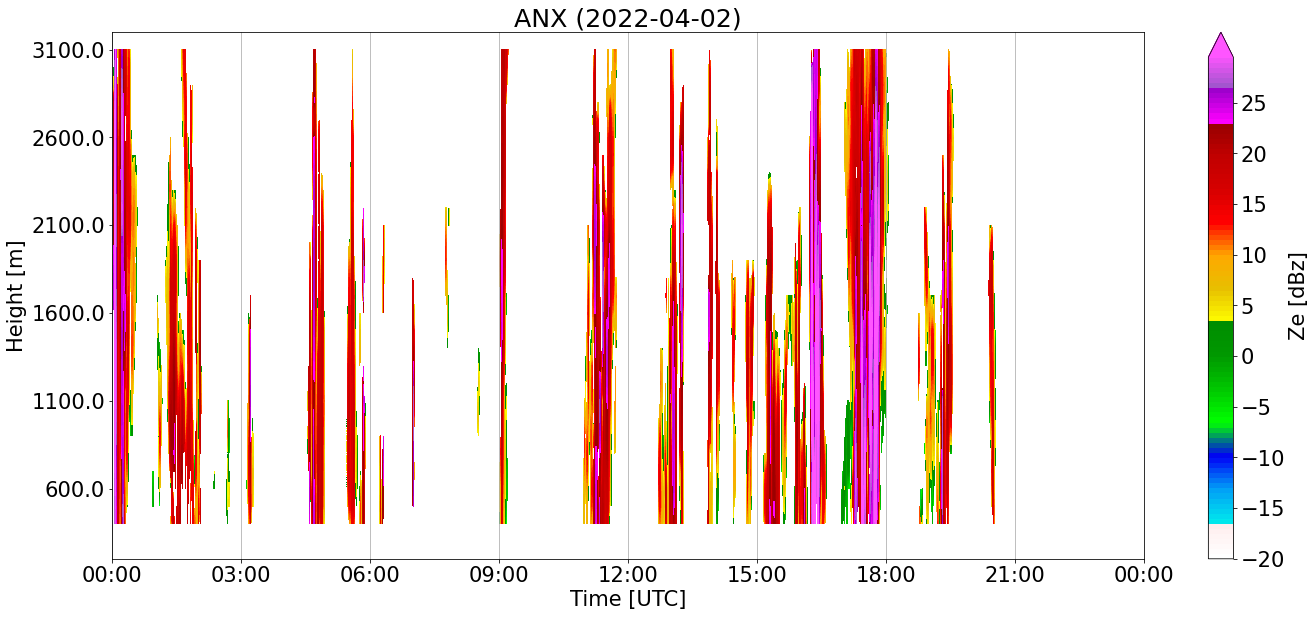

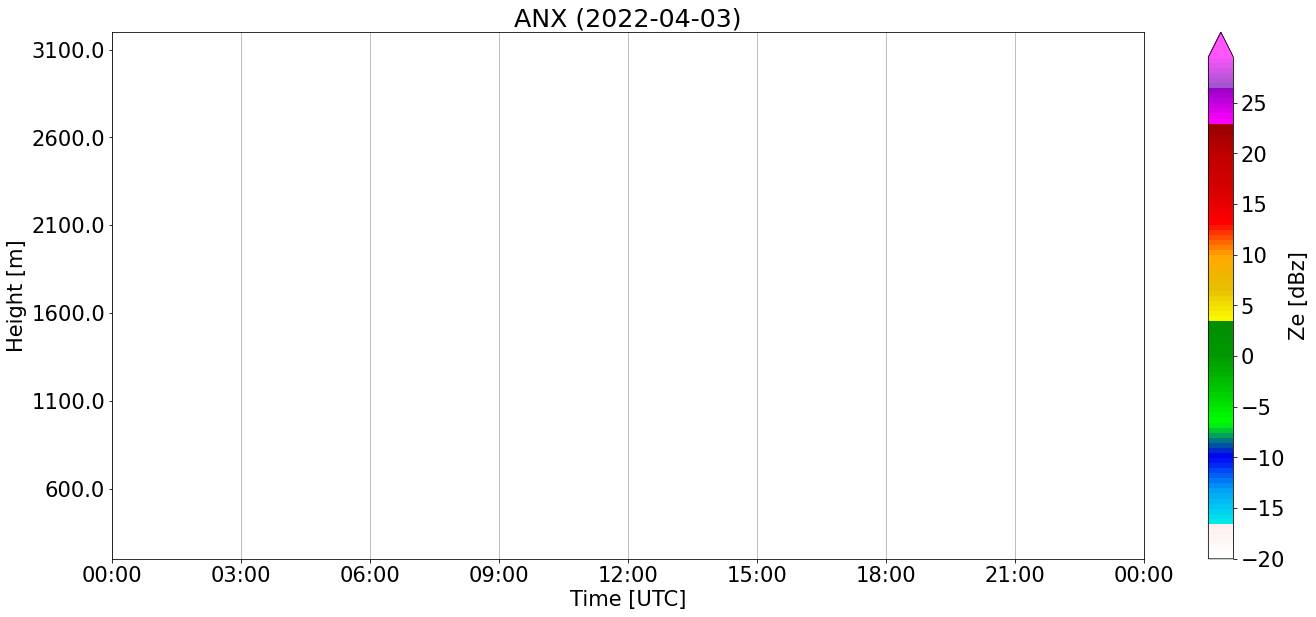

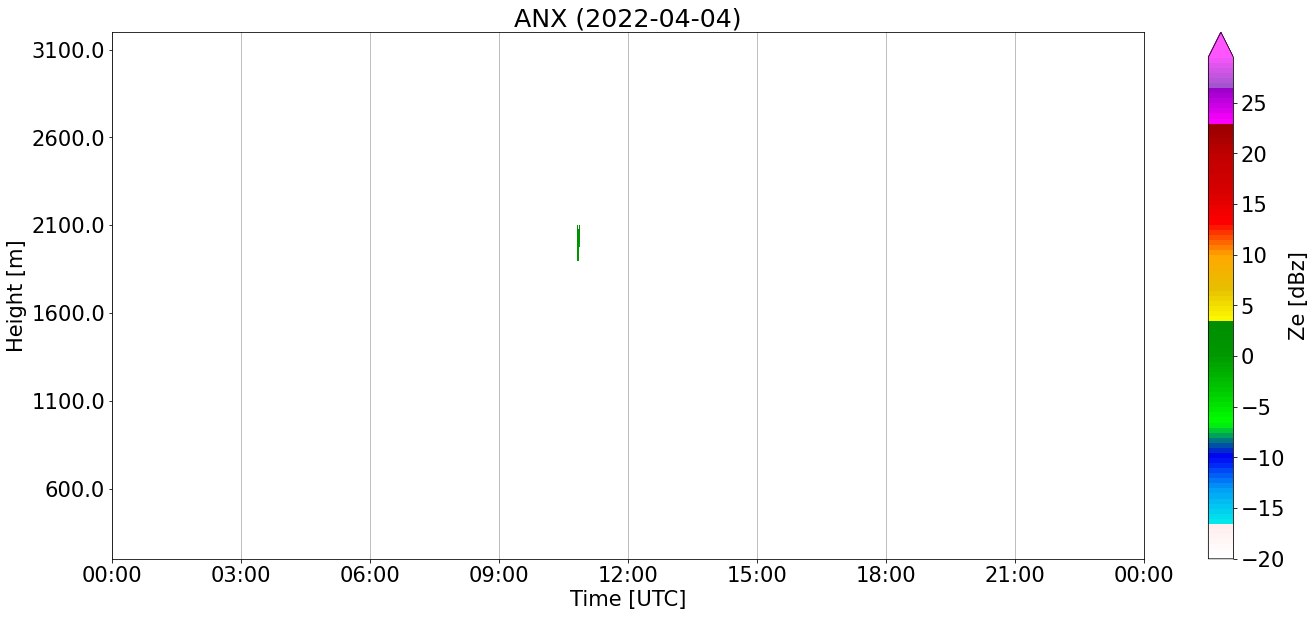

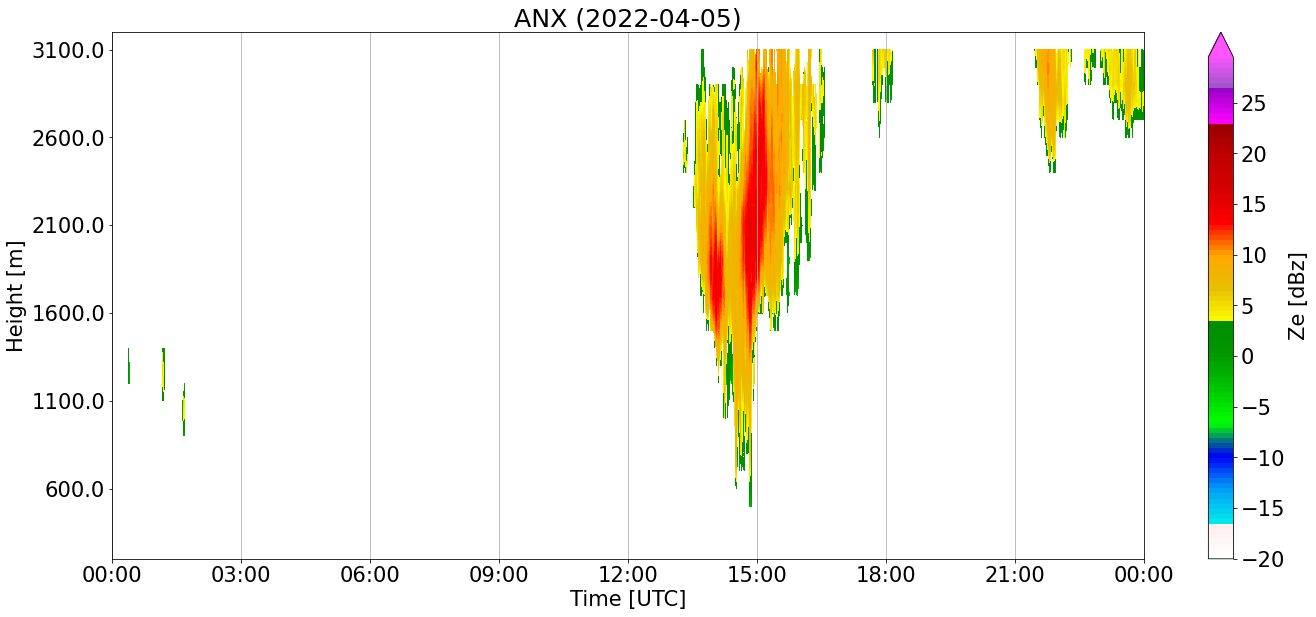

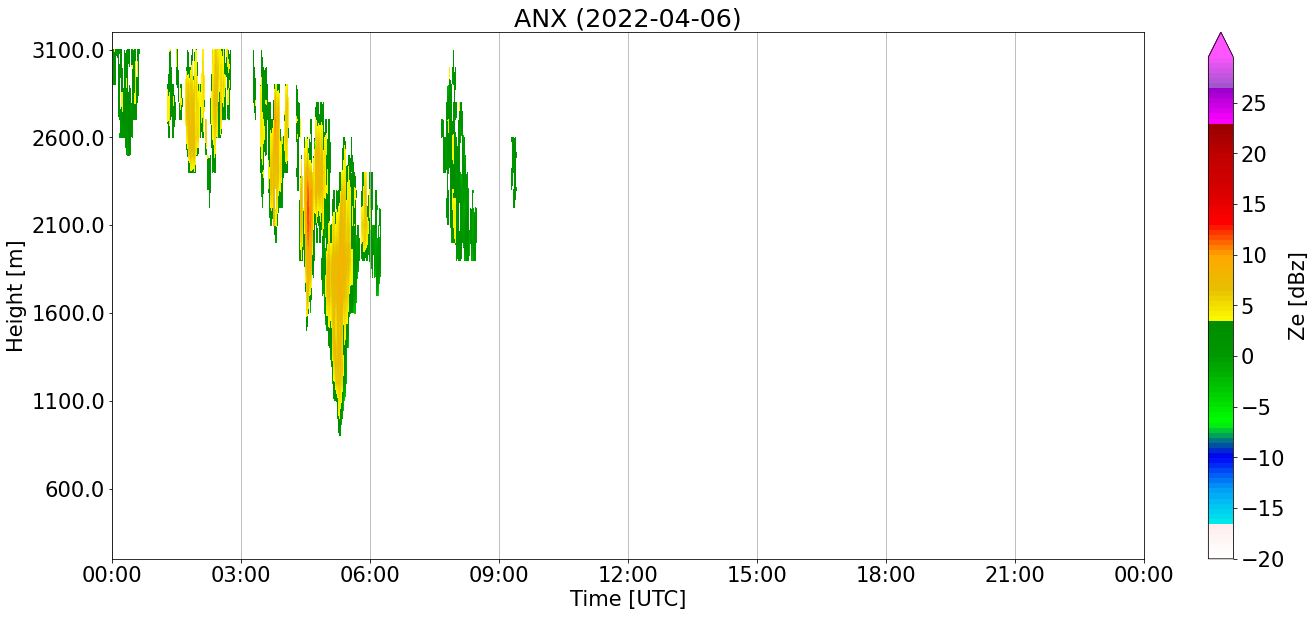

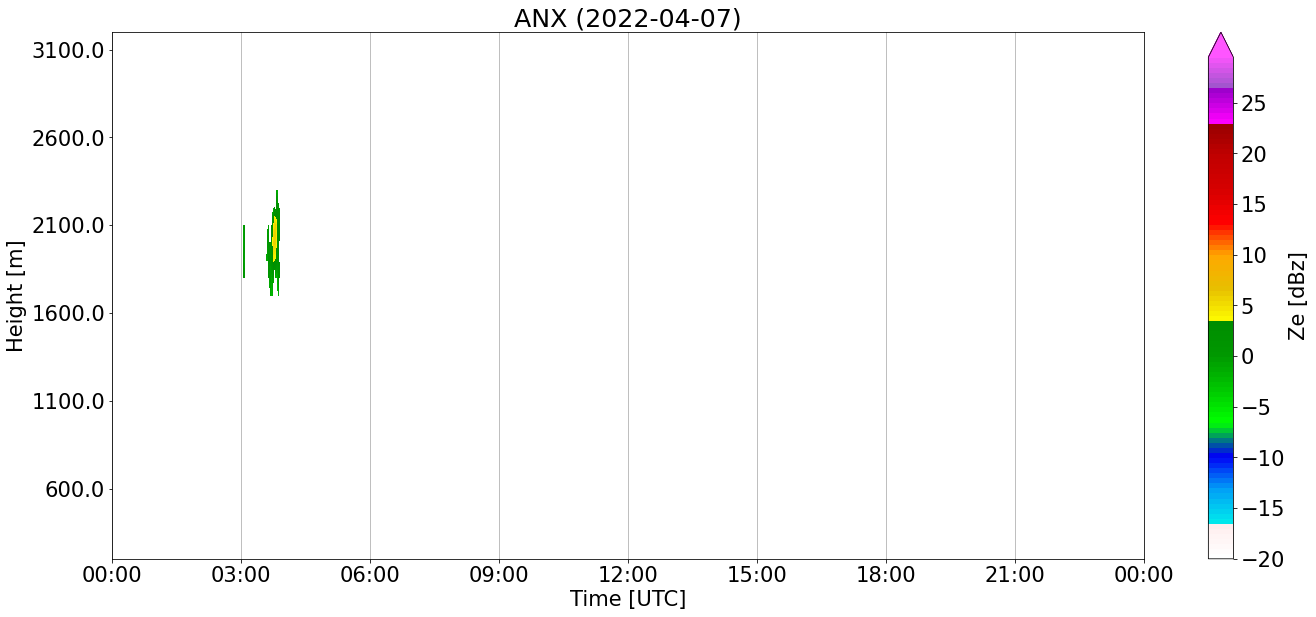

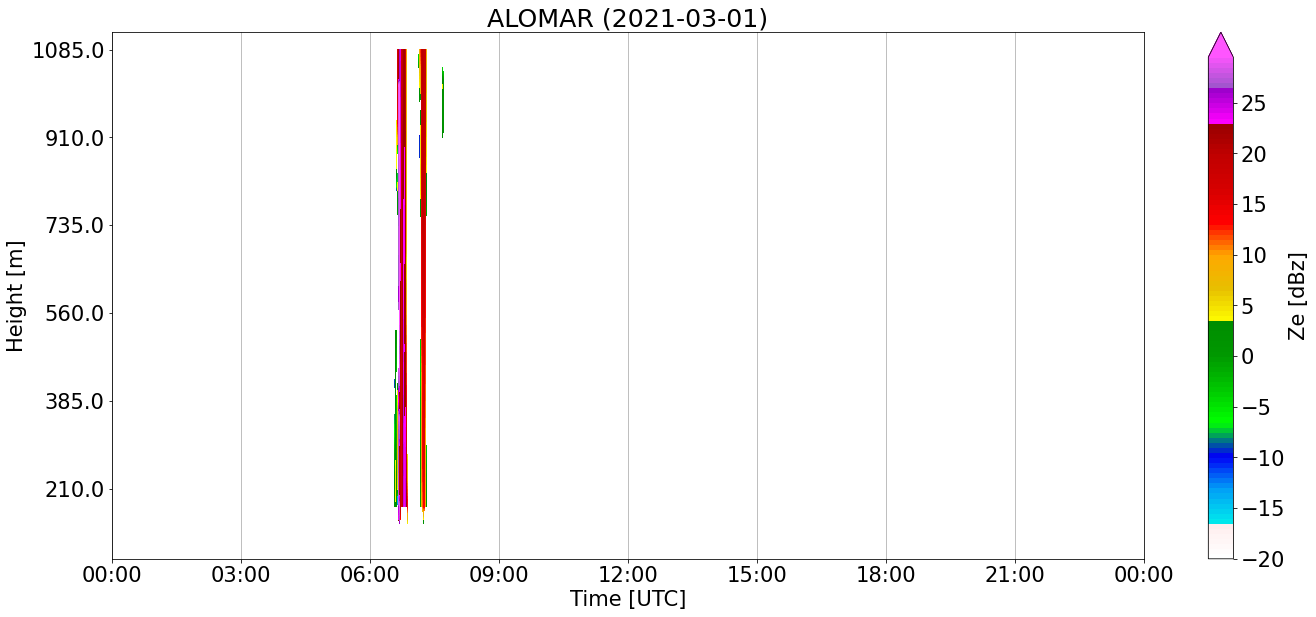

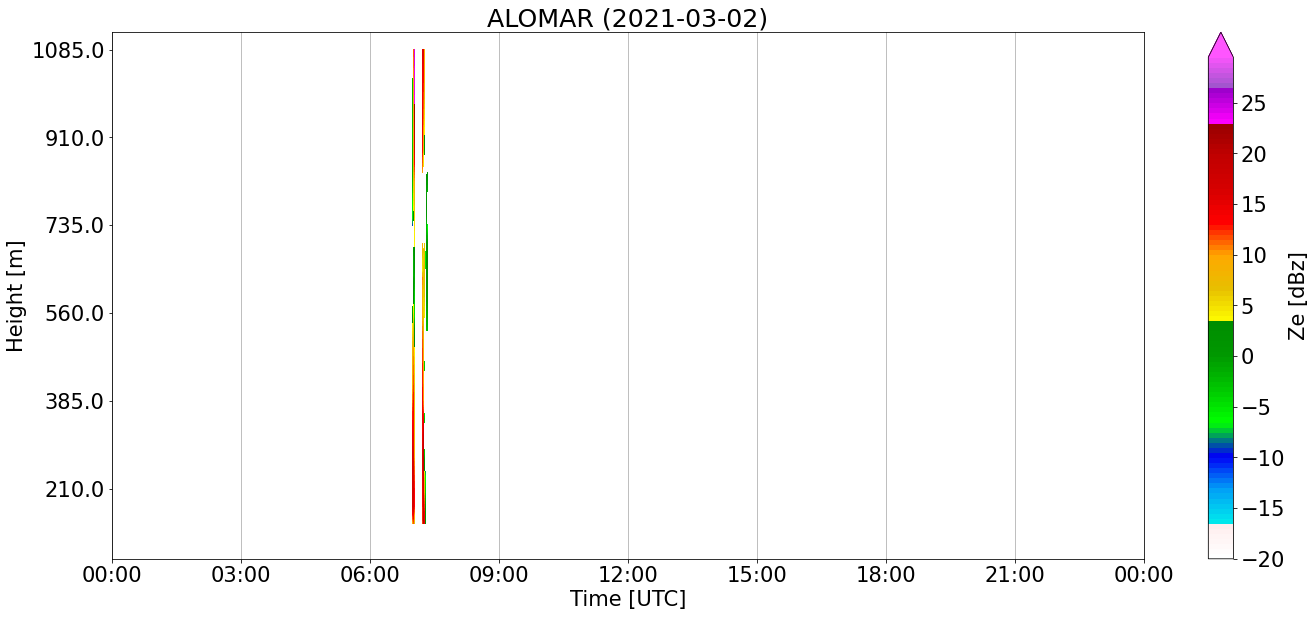

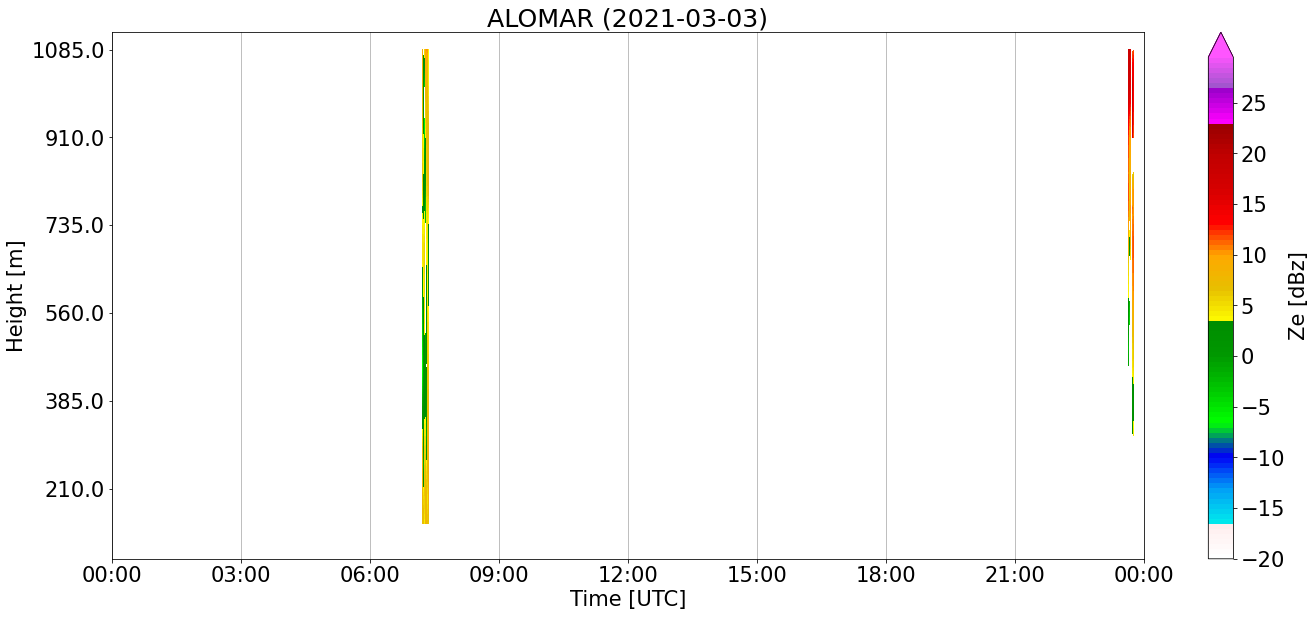

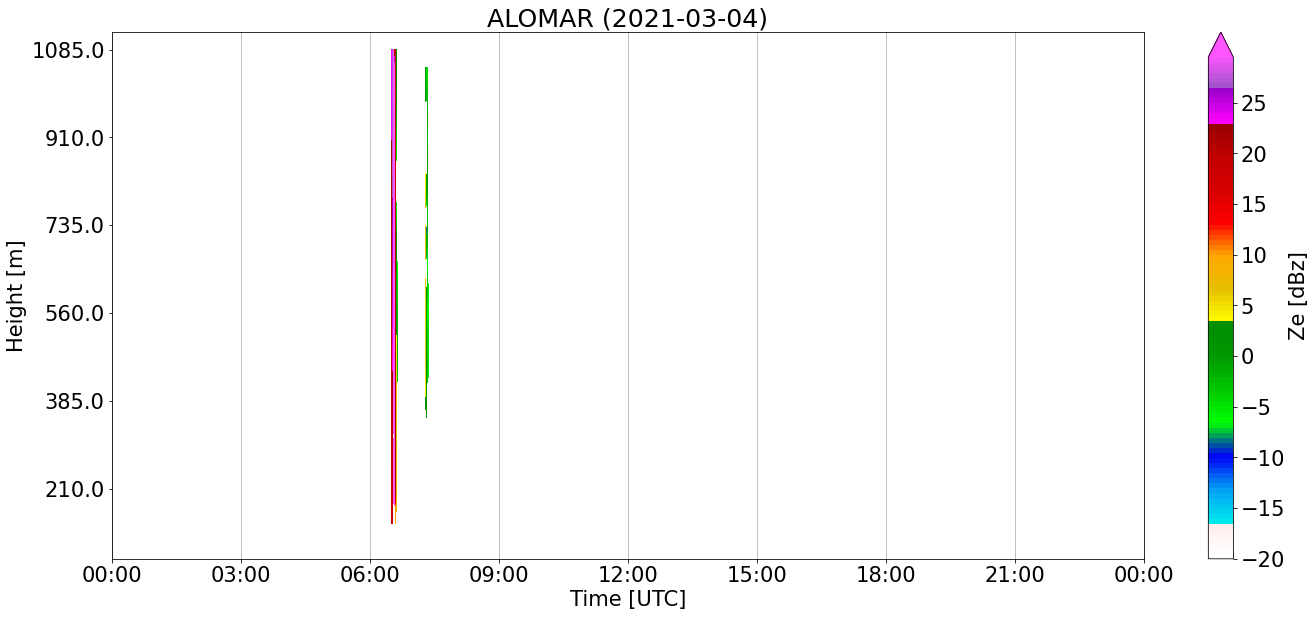

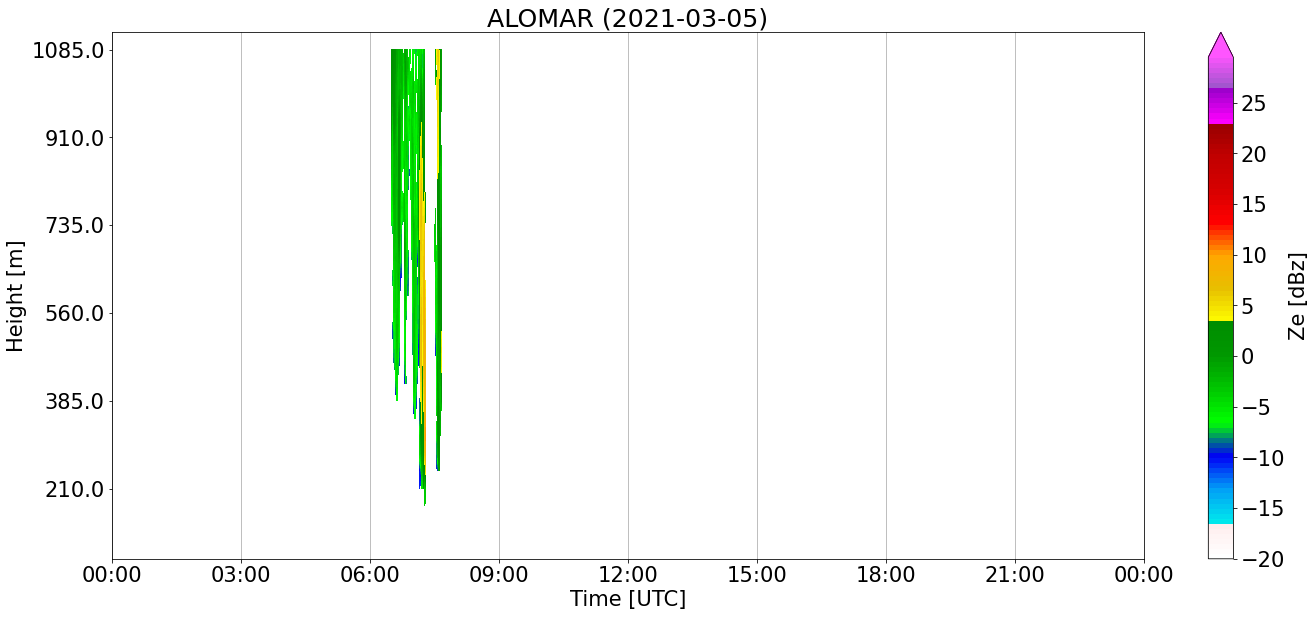

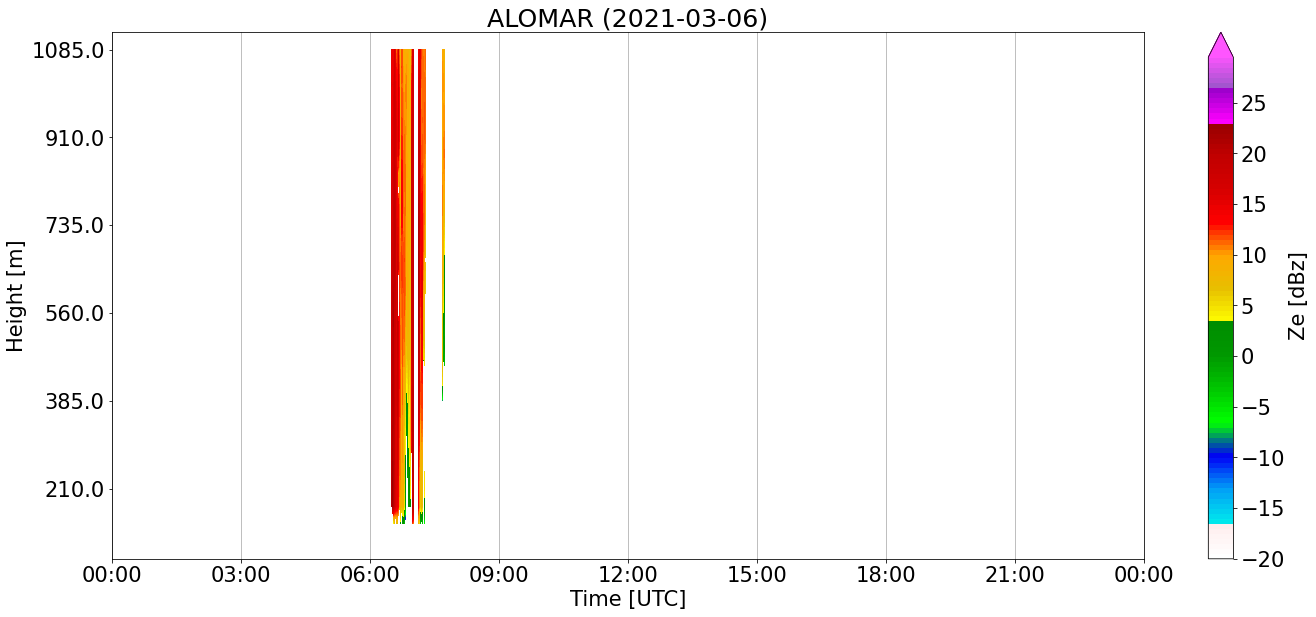

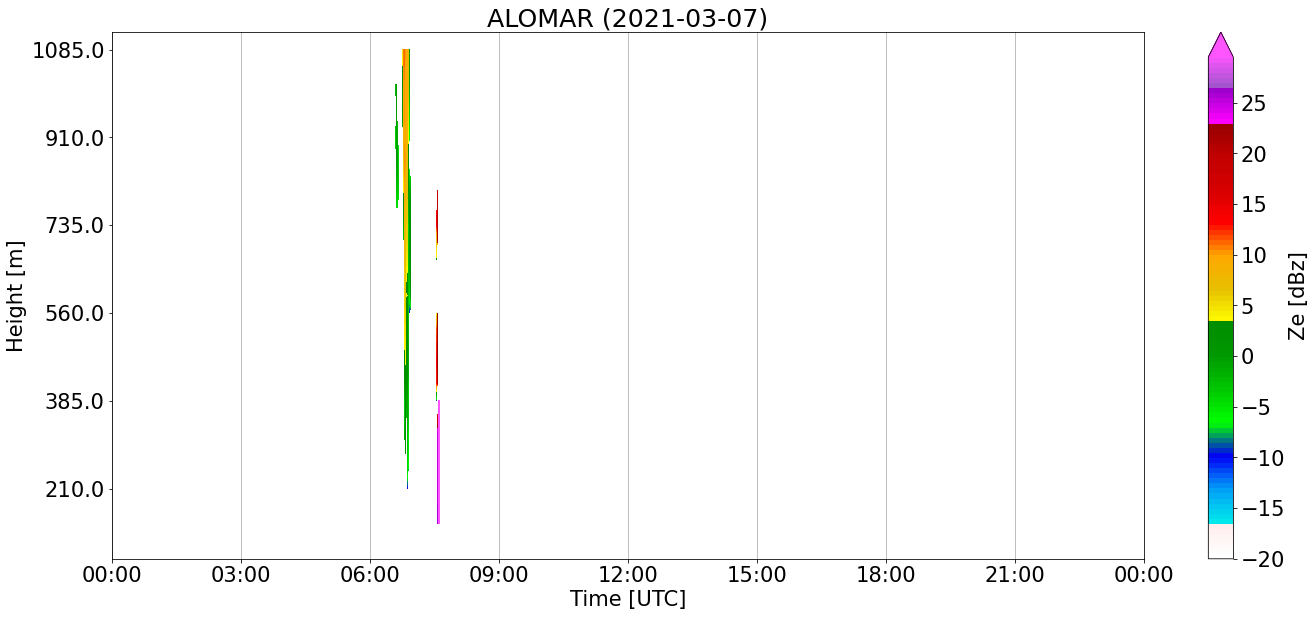

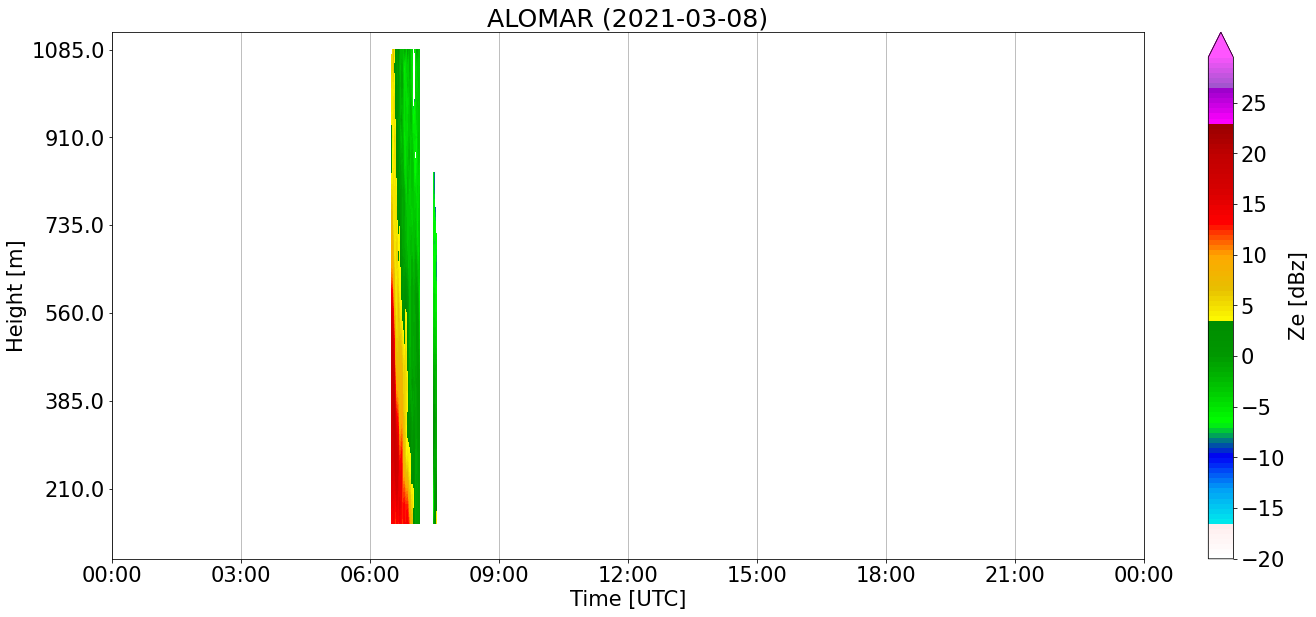

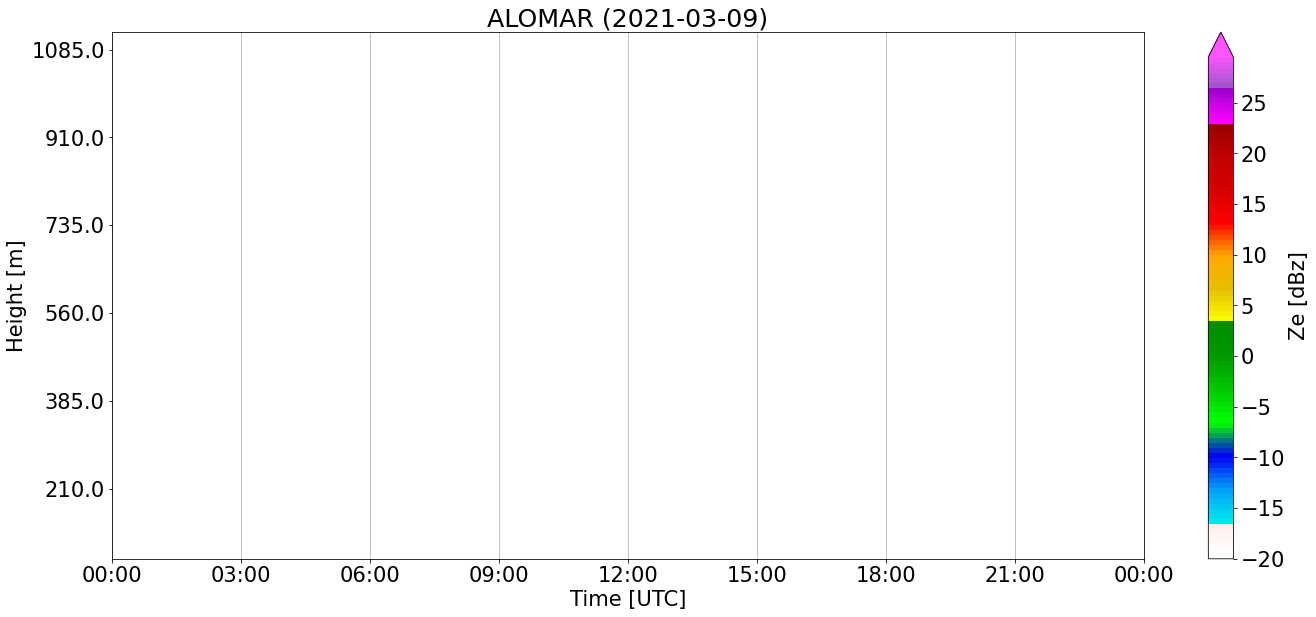

In [8]:
for key in mrr_in_dict.keys():
    # print(len(mrr_in_dict[key]))
    for j in range(len(mrr_in_dict[key])):
        date = mrr_in_dict[key][j][-11:-3]
        
        # Define name for figure
        figname = 'mrr_reflectivity_{}_{}'.format(key.split('.')[0], date)
        
        # Define start and end time of individual day
        day_start = datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S').strftime('%Y-%m-%d %H:%M:%S')
        day_end = (datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S') + datetime.timedelta(hours=23, minutes=59)).strftime('%Y-%m-%d %H:%M:%S')

        # select reflectivity and height to make radar reflectivity plot
        _Ze = ds_dict[key]['Ze'].sel(time = slice(day_start, day_end))
        _height = ds_dict[key]['height'].sel(time = slice(day_start, day_end))

        fig, axsm = plt.subplots(1, 1, figsize=[20,9])

        _Ze.plot.contourf(ax = axsm, x='time', y='range', vmin = -20, 
                            levels=levels, 
                            cmap=plt.get_cmap('pymeteo_radar'), extend='max')

        axsm.set(xlabel = "Time [UTC]", 
                ylabel = "Height [m]", yticklabels=_height.isel(time=0).values[::5],
                title ="{} ({})".format(key.split('.')[0], _Ze.time.dt.date[0].values))
        axsm.xaxis.grid()
        _xmax = (datetime.datetime.strptime(day_end, '%Y-%m-%d %H:%M:%S') + datetime.timedelta(minutes=1,)).strftime('%Y-%m-%d %H:%M:%S')
        axsm.set_xlim([day_start, _xmax])
        axsm.tick_params(axis='x', labelrotation=0, )
        plt.setp(axsm.get_xticklabels(), horizontalalignment="center")

        # Define the date format
        date_form = DateFormatter("%H:00")
        axsm.xaxis.set_major_formatter(date_form)
        
        plt.tight_layout();
        
        # save image to png
        plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=False)
